In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import os
import scipy.stats as stats
from scipy.special import logsumexp
import pandas as pd
import matplotlib.cm as cm
import math
import itertools
import random
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from random import random

from scipy.stats import linregress
from sklearn.linear_model import RANSACRegressor, LinearRegression
from scipy.stats import chi2_contingency, fisher_exact

import sys
sys.path.append('../src')

from em_clustering import (
    reassign_cells
)

from visualization import plot_overlap_matrix_figure

/home/ranade/miniconda3/lib/python3.6/site-packages/statsmodels/tools/_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


In [2]:
tumor ="t25"
infilename = f"../data/{tumor}/{tumor}.bin_count_table_all_cells.txt"
bincounts = pd.read_csv(infilename, sep="\t")
bincounts_no_WGS = pd.read_csv(f"../data/{tumor}/{tumor}.bincounts_without_WGS_segmentation.txt", sep="\t")


In [3]:
# Use ALL cells instead of filtered cells
all_cell_names = [col for col in bincounts.columns if col not in ['chrom', 'abstart', 'abend', 'lengths','loc.start','loc.end']]
cells = pd.read_csv(f"../data/{tumor}/{tumor}.not_broken_final_list.txt", header=None)[0].values


In [4]:
def make_random_seeds(q_data, num_seeds=10):
    """Generate multiple random seeds for EM initialization."""
    Seeds = []
    for i in range(num_seeds):
        s = []
        for j in range(len(q_data)):
            l2 = q_data.loc[j].values
            mi, mx = min(l2), max(l2)
            s.append([random() * (mx - mi) + mi, random() * (mx - mi) + mi])
        Seeds.append(s)
    return Seeds

In [5]:
def alg_on_best_of_seeds(all_data, num_seeds=10):
    """Run EM algorithm on multiple seeds and return best result."""
    q_data = all_data/all_data.sum(axis=0)
    Seeds = make_random_seeds(q_data, num_seeds)

    best_log_lik = -np.inf
    for s in Seeds:
        print("Trying new seed")
        logprob_NK, log_lik, mult_KV = EM_algorithm(all_data, s)
        if log_lik > best_log_lik:
            best_log_lik = log_lik
            best_logprob_NK = logprob_NK
            best_mult_KV = mult_KV
    
    return best_logprob_NK, best_log_lik, best_mult_KV

In [6]:
def EM_algorithm(data, s, Min_Diff=0.001, Max_Iter=20):
    """Core EM algorithm implementation."""
    obs_NV = np.array(data)[:,:].T
    log_likelihood = -np.inf
    
    mult_KV = np.array(s).T
    mult_KV = mult_KV / np.sum(mult_KV, axis=1)[:, np.newaxis]

    for i in range(Max_Iter):
        logmult_KV = np.log(mult_KV)
        logprob_NK = np.dot(obs_NV, logmult_KV.T)
        logsum_N = [logsumexp(list(x)) for x in logprob_NK]
        logprob_NK = np.add(logprob_NK, -np.array(logsum_N)[:, np.newaxis])

        membership_NK = np.exp(logprob_NK)
        log_likelihood_last = log_likelihood
        log_likelihood = np.sum(logsum_N)

        mult_KV = np.dot(membership_NK.T, obs_NV)
        mult_KV = mult_KV / np.sum(mult_KV, axis=1)[:, np.newaxis]
        
        log_diff = abs(log_likelihood-log_likelihood_last)
        if log_diff < Min_Diff:
            break
            
    if log_diff > 10*Min_Diff:
        return logprob_NK, -np.inf, mult_KV
    
    return logprob_NK, log_likelihood, mult_KV


In [7]:
def ratio_of_ratios_old(all_data, threshold=4/5, name=""):
    """Ratio of ratios analysis for population splitting."""
    logprob_NK, log_lik, mult_KV = alg_on_best_of_seeds(all_data)
    cluster1 = np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
    cluster2 = np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
    cells_1 = [all_data.columns[i] for i in cluster1]
    cells_2 = [all_data.columns[i] for i in cluster2]
    
    counts_1 = all_data[cells_1].sum(axis=1)
    counts_2 = all_data[cells_2].sum(axis=1)
    
    total_1 = np.sum(counts_1)
    total_2 = np.sum(counts_2)

    chi2_values = []
    for i in range(len(counts_1)):
        observed = np.array([
            [counts_1[i], total_1 - counts_1[i]],
            [counts_2[i], total_2 - counts_2[i]]
        ])
        chi2, p, dof, expected = chi2_contingency(observed, correction=False)
        chi2_values.append(chi2)
    chi2_values = np.array(chi2_values)
    top_indices = np.argsort(chi2_values)[-10:][::-1]
    bottom_indices = np.argsort(chi2_values)[:30]
    
    ratios_1 = []
    ratios_2 = []
    for i in top_indices:
        r1 = []
        r2 = []
        for j in bottom_indices:
            if j!=i:
                r1.append(counts_1[i]/counts_1[j])
                r2.append(counts_2[i]/counts_2[j])
        ratios_1.append(r1)
        ratios_2.append(r2)
    slopes = []
    fig,ax = plt.subplots(1, figsize=(10, 10))
    
    for r1, r2 in zip(ratios_1, ratios_2): 
        plt.scatter(r1, r2, alpha=0.5)
    for r1, r2 in zip(ratios_1, ratios_2): 
        model = RANSACRegressor(LinearRegression(fit_intercept=False)).fit(np.array(r1).reshape(-1, 1), np.array(r2))
        slopes.append(model.estimator_.coef_[0])
        x_fit = np.linspace(min(r1), max(r1), 100).reshape(-1, 1)
        y_fit = model.predict(x_fit)
        plt.plot(x_fit, y_fit, linestyle='dashed')

    x = np.linspace(0, 10, 50)
    plt.plot(x, x, color='black')  # y=x line 

    y = threshold * x
    plt.plot(x, y, color='grey')  # y=(4/5)x line
    y = (1/threshold) * x
    plt.plot(x, y, color='grey')  # y=(5/4)x line

    l1 = str(len(cells_1))
    l2 = str(len(cells_2))
    plt.title(f"Ratio of Ratios Plot {name}1({l1}) and {name}2({l2})")
    plt.xlim([0,10])
    plt.ylim([0,10])
    return slopes, top_indices, bottom_indices, cells_1, cells_2, mult_KV


In [8]:
def recursive_em_split_old(data, cell_list, mult_KV_param=None, threshold=3/4, max_depth=10, current_depth=0, name="A"):
    """
    Recursively splits cell populations using EM algorithm until slopes are within threshold.
    """
    print(f"{'  ' * current_depth}Processing population {name} with {len(cell_list)} cells")
    
    if mult_KV_param is None:
        current_data = data[cell_list]
        q_data = current_data / current_data.sum(axis=0)
        mult_KV_param = q_data.mean(axis=1).values
    
    threshold = min(threshold, 1/threshold)
    if current_depth >= max_depth:
        print(f"{'  ' * current_depth}Max depth reached for {name}")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
    
    if len(cell_list) < 50:
        print(f"{'  ' * current_depth}Population {name} too small to split")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
    
    try:
        current_data = data[cell_list]
        slopes, top_indices, bottom_indices, cells_1, cells_2, unassigned = ratio_of_ratios_old(current_data, threshold, name)
        
        max_slope = max(slopes)
        min_slope = min(slopes)
        
        print(f"{'  ' * current_depth}Slopes for {name}: max={max_slope:.3f}, min={min_slope:.3f}")
        
        if threshold <= min_slope and max_slope <= 1/threshold:
            print(f"{'  ' * current_depth}Split rejected for {name}: slopes between {threshold:.3f} and {1/threshold:.3f}")
            return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
        
        if len(cells_1) < 25 or len(cells_2) < 25:
            print(f"{'  ' * current_depth}Split produces too small subpopulations for {name}")
            return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
        
        print(f"{'  ' * current_depth}Split accepted for {name}: {len(cells_1)} + {len(cells_2)} cells")
        
        result = {}
        
        sub_result_1 = recursive_em_split_old(
            data, cells_1, mult_KV[0], threshold, max_depth, current_depth + 1, name + "1"
        )
        result.update(sub_result_1)
        
        sub_result_2 = recursive_em_split_old(
            data, cells_2, mult_KV[1], threshold, max_depth, current_depth + 1, name + "2"
        )
        result.update(sub_result_2)
        
        return result
        
    except Exception as e:
        print(f"{'  ' * current_depth}Error splitting {name}: {e}")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}


In [9]:
bincounts.head()

,chrom,loc.start,loc.end,abstart,abend,TGGCCTGAGGTAACACA,TGCCAAAAGCGTTTATT,GCAAATACCTGCCGTCT,GTTAAGTTTAGTGTAGC,GCATCGACATGAACAGC,...,TTTCGATTCCAGTGAGT,TTTTGGAAAATGGTAAT,TTTTGGAGCGTTATAAC,TTTTGGATGAGGTAATG,TTTTGGGACTACAATAT,TTTTGGGGCTATAATTG,TTTTGGTAATTTCTTCG,TTTTGGTGTTAAGCTAA,TTTTGGTTGCTGAGTGT,TTTTGGTTTACGACTCT
0,chr1,0,15737727,0,15737727,365,305,311,289,212,...,5,31,72,12,11,49,89,70,19,106
1,chr1,16309376,19838791,16309376,19838791,114,68,84,91,51,...,1,10,2,0,1,17,24,15,8,8
2,chr1,20399617,29621787,20399617,29621787,238,210,251,205,118,...,6,23,45,3,3,31,71,38,27,1
3,chr1,30315354,35903486,30315354,35903486,93,109,97,133,91,...,16,11,20,1,4,12,55,27,8,1
4,chr1,36461413,109420217,36461413,109420217,2070,1806,1970,1868,1948,...,76,171,342,27,24,108,569,360,209,28


In [10]:
M = bincounts[all_cell_names].sum().mean()

In [11]:
previous_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_C.txt", sep="\t")
normal_cells = previous_df[previous_df['normal_population']==True]["cell"].values


In [12]:
#pick the largest tumor cluster with more than 100 cells
counts = Counter(previous_df[previous_df['normal_population']==False]["population"])
largest_cluster = max((pop for pop, cnt in counts.items() if cnt > 100), key=counts.get)

In [13]:
previous_df.head()

,cell,population,normal_population
0,AAAACCAGTGAGGAACT,C11,False
1,AAAACCATGGATGTAGC,C11,False
2,AAAACCGACCATTTAGG,C11,False
3,AAAACCGCCTCTAATGC,C11,False
4,AAAATGACTGGCAATGC,C11,False


In [14]:
tumor_cells = previous_df[previous_df['normal_population']==False]["cell"].values
#tumor_cells = previous_df[previous_df['population']==largest_cluster]["cell"].values
#randomly select 100 normal and 100 tumor cells
normal_sample = np.random.choice(normal_cells, 100, replace=False)
tumor_sample = np.random.choice(tumor_cells, 100, replace=False)
for c1, c2 in zip(normal_sample, tumor_sample):
    bincounts[c1+"_"+c2] = bincounts[c1] + bincounts[c2]
# for c1, c2 in zip(normal_sample, tumor_sample):
#     bincounts[c1+"_"+c2] = (bincounts[c1]/bincounts[c1].sum() + bincounts[c2]/bincounts[c2].sum())*M


In [15]:
bincounts.to_csv(f"../data/{tumor}/{tumor}.bin_count_table_all_cells_with_collisions.txt", sep="\t", index=False)

In [16]:
collisions = [c1+"_"+c2 for c1, c2 in zip(normal_sample, tumor_sample)]

In [17]:

all_cell_names = [col for col in bincounts.columns if col not in ['chrom', 'abstart', 'abend', 'lengths','loc.start','loc.end']]

In [18]:
# Prepare data
data = bincounts[["chrom", "abstart", "abend"] + all_cell_names].copy()
data["lengths"] = data["abend"] - data["abstart"]
all_data = data[list(cells)+collisions].copy()
# data_no_WGS = bincounts_no_WGS[["chrom", "abstart", "abend"] + all_cell_names].copy()
# data_no_WGS["lengths"] = data_no_WGS["abend"] - data_no_WGS["abstart"]
# all_data_no_WGS = data_no_WGS[cells].copy()
# with_broken = data[all_cell_names].copy()

In [19]:
# # 2. Run Recursive old EM Splitting (two independent runs)
# print("Running recursive EM split A...")
# final_populations_A = recursive_em_split_old(
#     all_data, cells, 
#     threshold=3/4, max_depth=10, name="A"
# )

In [20]:
all_data.head()

,AAAACCAAATCCAGACT,AAAACCAACAAGAGACT,AAAACCAACCTGTCTGT,AAAACCAAGCGTGGTCA,AAAACCAAGGCCCAACG,AAAACCAAGGCCCAATA,AAAACCAGAACCTAATG,AAAACCAGTGAGATTCC,AAAACCAGTGAGGAACT,AAAACCATGGATGTAGC,...,TATTTGGATAGAGTTCT_AAATCGTTCCAGACAGC,GTAACCGTTAGCTGAGT_GAAGCCTAAACCAGAAG,GGGTCTGAACAATCATC_GTTTCGTGAACAATTCC,GTTTCGAAATCCTCTGT_TTTTGGGAACAACAACG,TTGGACAGTGAGACTAG_TTGCGTACATGAACTAG,GTGCATGTTAGCTGATA_GCAAATAAGCGTGATTA,TGAAACGGCTATGTACA_AGCGAATAAACCTGACG,GGGATCAACCTGTATAG_TGCCAAGCCTCTTGAAC,ATGGTTTTAAGGAGAAG_AGCAATGGTGACCTAAG,ATAGCCTGTTAAGCATA_CAGGCAATTGGTGTAGC
0,46,70,172,92,54,51,119,37,98,186,...,408,316,235,286,273,430,260,165,248,291
1,18,32,50,24,11,21,34,17,30,53,...,100,100,59,70,79,113,74,54,54,54
2,50,58,104,59,34,36,78,24,60,96,...,281,200,193,183,198,264,204,110,160,169
3,29,39,40,35,23,25,27,23,40,77,...,150,84,99,69,91,152,128,69,71,105
4,353,482,886,573,316,459,468,294,451,960,...,2211,1667,1667,1229,1564,2291,1225,1545,1209,1677


In [21]:
# num_seeds = 10
# q_data = all_data/all_data.sum(axis=0)
# Seeds = make_random_seeds(q_data, num_seeds)

# best_log_lik = -np.inf
# seed_results = {"log_lik": [], "mult_KV": [], "logprob_NK": []}
# for s in Seeds:
#     print("Trying new seed")
#     logprob_NK, log_lik, mult_KV = EM_algorithm(all_data, s)
#     seed_results["log_lik"].append(log_lik)
#     seed_results["mult_KV"].append(mult_KV)
#     seed_results["logprob_NK"].append(logprob_NK)
#     if log_lik > best_log_lik:
#         best_log_lik = log_lik
#         best_logprob_NK = logprob_NK
#         best_mult_KV = mult_KV

In [22]:
# population_splits = []
# for logprob_NK in seed_results["logprob_NK"]:
#     cluster1 = np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
#     cluster2 = np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
#     cells_1 = [all_data.columns[i] for i in cluster1]
#     cells_2 = [all_data.columns[i] for i in cluster2]
#     population_splits.append((cells_1, cells_2))

In [23]:
# for cells_1, cells_2 in population_splits:      
#     print(f"Population split: {len(cells_1)} cells in cluster 1, {len(cells_2)} cells in cluster 2")

In [24]:
#pop_1, pop_2 = population_splits[0]

In [25]:
# sub_data = all_data[pop_1]
# num_seeds = 10
# q_data = sub_data/sub_data.sum(axis=0)
# Seeds = make_random_seeds(q_data, num_seeds)

# best_log_lik = -np.inf
# seed_results = {"log_lik": [], "mult_KV": [], "logprob_NK": []}
# for s in Seeds:
#     print("Trying new seed")
#     logprob_NK, log_lik, mult_KV = EM_algorithm(sub_data, s)
#     seed_results["log_lik"].append(log_lik)
#     seed_results["mult_KV"].append(mult_KV)
#     seed_results["logprob_NK"].append(logprob_NK)
#     if log_lik > best_log_lik:
#         best_log_lik = log_lik
#         best_logprob_NK = logprob_NK
#         best_mult_KV = mult_KV

In [26]:
# population_splits_1 = []
# for logprob_NK in seed_results["logprob_NK"]:
#     cluster1 = np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
#     cluster2 = np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
#     cells_1 = [all_data.columns[i] for i in cluster1]
#     cells_2 = [all_data.columns[i] for i in cluster2]
#     population_splits_1.append((cells_1, cells_2))

In [27]:
# for cells_1, cells_2 in population_splits_1:      
#     print(f"Population split: {len(cells_1)} cells in cluster 1, {len(cells_2)} cells in cluster 2")

In [28]:
# sub_data = all_data[pop_2]
# num_seeds = 10
# q_data = sub_data/sub_data.sum(axis=0)
# Seeds = make_random_seeds(q_data, num_seeds)

# best_log_lik = -np.inf
# seed_results = {"log_lik": [], "mult_KV": [], "logprob_NK": []}
# for s in Seeds:
#     print("Trying new seed")
#     logprob_NK, log_lik, mult_KV = EM_algorithm(sub_data, s)
#     seed_results["log_lik"].append(log_lik)
#     seed_results["mult_KV"].append(mult_KV)
#     seed_results["logprob_NK"].append(logprob_NK)
#     if log_lik > best_log_lik:
#         best_log_lik = log_lik
#         best_logprob_NK = logprob_NK
#         best_mult_KV = mult_KV

In [29]:
# population_splits_2 = []
# for logprob_NK in seed_results["logprob_NK"]:
#     cluster1 = np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
#     cluster2 = np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
#     cells_1 = [all_data.columns[i] for i in cluster1]
#     cells_2 = [all_data.columns[i] for i in cluster2]
#     population_splits_2.append((cells_1, cells_2))

In [30]:
# for cells_1, cells_2 in population_splits_2:      
#     print(f"Population split: {len(cells_1)} cells in cluster 1, {len(cells_2)} cells in cluster 2")

In [31]:
#cells_1, cells_2 = population_splits_1[0]
#cells_3, cells_4 = population_splits_1[2]

In [32]:
#len(cells_1), len(cells_2)

In [33]:
# sub_data = all_data[cells_2]
# num_seeds = 10
# q_data = sub_data/sub_data.sum(axis=0)
# Seeds = make_random_seeds(q_data, num_seeds)

# best_log_lik = -np.inf
# seed_results = {"log_lik": [], "mult_KV": [], "logprob_NK": []}
# for s in Seeds:
#     print("Trying new seed")
#     logprob_NK, log_lik, mult_KV = EM_algorithm(sub_data, s)
#     seed_results["log_lik"].append(log_lik)
#     seed_results["mult_KV"].append(mult_KV)
#     seed_results["logprob_NK"].append(logprob_NK)
#     if log_lik > best_log_lik:
#         best_log_lik = log_lik
#         best_logprob_NK = logprob_NK
#         best_mult_KV = mult_KV

In [34]:
# population_splits_3 = []
# for logprob_NK in seed_results["logprob_NK"]:
#     cluster1 = np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
#     cluster2 = np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
#     cells_1 = [all_data.columns[i] for i in cluster1]
#     cells_2 = [all_data.columns[i] for i in cluster2]
#     population_splits_3.append((cells_1, cells_2))

In [35]:
# for cells_1, cells_2 in population_splits_3:      
#     print(f"Population split: {len(cells_1)} cells in cluster 1, {len(cells_2)} cells in cluster 2")

In [36]:
# Calculate pairwise overlap between all population splits
def calculate_overlap(cells_a, cells_b):
    """Calculate Jaccard similarity between two cell lists."""
    set_a = set(cells_a)
    set_b = set(cells_b)
    intersection = len(set_a & set_b)
    union = len(set_a | set_b)
    return intersection / union if union > 0 else 0

# # Build overlap matrix for all splits
# num_splits = len(population_splits)
# overlap_matrix = np.zeros((num_splits, num_splits))

# for i in range(num_splits):
#     for j in range(num_splits):
#         cells_1_i, cells_2_i = population_splits[i]
#         cells_1_j, cells_2_j = population_splits[j]
        
#         # Compare cluster 1 to cluster 1 and cluster 2 to cluster 2
#         overlap_11 = calculate_overlap(cells_1_i, cells_1_j)
#         overlap_22 = calculate_overlap(cells_2_i, cells_2_j)
        
#         # Also compare cluster 1 to cluster 2 (in case labels are flipped)
#         overlap_12 = calculate_overlap(cells_1_i, cells_2_j)
#         overlap_21 = calculate_overlap(cells_2_i, cells_1_j)
        
#         # Take the maximum overlap (accounting for potential label swapping)
#         overlap_matrix[i, j] = max(
#             (overlap_11 + overlap_22) / 2,
#             (overlap_12 + overlap_21) / 2
#         )


In [37]:
# # Display overlap matrix
# print("Overlap matrix between splits:")
# print(overlap_matrix)


In [38]:
# # Find the largest group of mutually high-consensus splits
# consensus_threshold = 0.9

# # Create adjacency matrix (1 if overlap > threshold, 0 otherwise)
# adjacency = (overlap_matrix > consensus_threshold).astype(int)

# # Find connected components using a greedy approach
# visited = set()
# consensus_groups = []

# for i in range(num_splits):
#     if i in visited:
#         continue
    
#     # Start a new group with split i
#     current_group = {i}
#     candidates = set(range(num_splits)) - visited - {i}
    
#     # Keep adding splits that have high consensus with ALL members of current group
#     while candidates:
#         added_any = False
#         for candidate in list(candidates):
#             # Check if candidate has high overlap with all members of current group
#             if all(overlap_matrix[candidate, member] > consensus_threshold 
#                    for member in current_group):
#                 current_group.add(candidate)
#                 candidates.remove(candidate)
#                 added_any = True
        
#         # If no new splits were added, this group is complete
#         if not added_any:
#             break
    
#     visited.update(current_group)
#     consensus_groups.append(current_group)

# # Find the largest consensus group
# largest_group = max(consensus_groups, key=len)
# print(f"Found {len(consensus_groups)} consensus groups")
# print(f"Largest group has {len(largest_group)} splits: {largest_group}")

# # Now create the consensus split from the largest group
# consensus_split_indices = list(largest_group)
# print(f"\nUsing {len(consensus_split_indices)} splits for consensus")

# # ALIGN ALL SPLITS TO HAVE CONSISTENT LABELING
# # Use the first split as reference
# reference_idx = consensus_split_indices[0]
# ref_cells_1, ref_cells_2 = population_splits[reference_idx]

# aligned_splits = []
# for idx in consensus_split_indices:
#     cells_1, cells_2 = population_splits[idx]
    
#     # Check overlap with reference
#     overlap_11 = calculate_overlap(cells_1, ref_cells_1)
#     overlap_12 = calculate_overlap(cells_1, ref_cells_2)
    
#     # If cluster 1 overlaps more with ref cluster 2, flip the labels
#     if overlap_12 > overlap_11:
#         aligned_splits.append((cells_2, cells_1))  # Flipped
#     else:
#         aligned_splits.append((cells_1, cells_2))  # Not flipped

# # For each cell, count how many times it appears in cluster 1 vs cluster 2
# cell_votes = defaultdict(lambda: {'cluster1': 0, 'cluster2': 0})

# for cells_1, cells_2 in aligned_splits:
#     for cell in cells_1:
#         cell_votes[cell]['cluster1'] += 1
#     for cell in cells_2:
#         cell_votes[cell]['cluster2'] += 1

# # Assign cells based on majority vote
# consensus_cluster1 = []
# consensus_cluster2 = []
# unassigned_cells = []

# vote_threshold = len(aligned_splits) * 0.8  # 80% agreement required

# for cell in all_data.columns:
#     votes = cell_votes[cell]
#     total_votes = votes['cluster1'] + votes['cluster2']
    
#     if votes['cluster1'] >= vote_threshold:
#         consensus_cluster1.append(cell)
#     elif votes['cluster2'] >= vote_threshold:
#         consensus_cluster2.append(cell)
#     else:
#         unassigned_cells.append(cell)

# print(f"\nConsensus results:")
# print(f"Cluster 1: {len(consensus_cluster1)} cells")
# print(f"Cluster 2: {len(consensus_cluster2)} cells")
# print(f"Unassigned (stragglers): {len(unassigned_cells)} cells")

In [39]:
def consensus_split_population(all_data, consensus_threshold=0.9, min_consensus=0.3, num_seeds=50):
    """
    Select split by descending log-likelihood, but require minimum consensus support.
    A candidate split is accepted if at least `min_consensus` fraction of OTHER splits
    have overlap >= `consensus_threshold` (flip-aware).
    """
    q_data = all_data / all_data.sum(axis=0)
    Seeds = make_random_seeds(q_data, num_seeds)

    split_records = []
    for s in Seeds:
        logprob_NK, log_lik, mult_KV = EM_algorithm(all_data, s)

        # Skip non-converged / invalid runs
        if not np.isfinite(log_lik):
            continue

        diffs = np.array([x - y for x, y in logprob_NK])
        cluster1 = np.where(diffs > 0)[0]
        cluster2 = np.where(diffs < 0)[0]
        unassigned = np.where(diffs == 0)[0]

        cells_1 = [all_data.columns[i] for i in cluster1]
        cells_2 = [all_data.columns[i] for i in cluster2]
        unassigned_cells = [all_data.columns[i] for i in unassigned]

        # Keep only proper binary splits
        if len(cells_1) == 0 or len(cells_2) == 0:
            continue

        split_records.append({
            "log_lik": log_lik,
            "cells_1": cells_1,
            "cells_2": cells_2,
            "unassigned": unassigned_cells,
            "mult_KV": mult_KV
        })

    if len(split_records) == 0:
        print("No valid EM splits found.")
        return None, None, list(all_data.columns)

    # Sort by log-likelihood (highest first)
    split_records.sort(key=lambda r: r["log_lik"], reverse=True)

    # If only one valid split exists, accept it directly
    if len(split_records) == 1:
        chosen = split_records[0]
        print("Only one valid split found; accepting highest log-likelihood split.")
        print(f"Cluster 1: {len(chosen['cells_1'])} cells")
        print(f"Cluster 2: {len(chosen['cells_2'])} cells")
        print(f"Unassigned (stragglers): {len(chosen['unassigned'])} cells")
        return chosen["cells_1"], chosen["cells_2"], chosen["unassigned"]

    # Evaluate candidates in descending log-likelihood order
    n = len(split_records)
    for i, cand in enumerate(split_records):
        supporters = 0

        for j, other in enumerate(split_records):
            if i == j:
                continue

            c1_i, c2_i = cand["cells_1"], cand["cells_2"]
            c1_j, c2_j = other["cells_1"], other["cells_2"]

            overlap_11 = calculate_overlap(c1_i, c1_j)
            overlap_22 = calculate_overlap(c2_i, c2_j)
            overlap_12 = calculate_overlap(c1_i, c2_j)
            overlap_21 = calculate_overlap(c2_i, c1_j)

            overlap_score = max(
                (overlap_11 + overlap_22) / 2,
                (overlap_12 + overlap_21) / 2
            )

            if overlap_score >= consensus_threshold:
                supporters += 1

        support_fraction = supporters / (n - 1)

        if support_fraction >= min_consensus:
            print(
                f"Selected split rank={i+1} by log-likelihood "
                f"(log_lik={cand['log_lik']:.4f}) with support={support_fraction:.3f}"
            )
            print(f"Cluster 1: {len(cand['cells_1'])} cells")
            print(f"Cluster 2: {len(cand['cells_2'])} cells")
            print(f"Unassigned (stragglers): {len(cand['unassigned'])} cells")
            return cand["cells_1"], cand["cells_2"], cand["unassigned"], cand["mult_KV"]

    print("No split met minimum consensus support in log-likelihood order.")
    return None, None, list(all_data.columns), None

In [40]:
# def consensus_split_population(all_data, consensus_threshold = 0.9, min_consensus = 0.3, num_seeds=50):
#     q_data = all_data/all_data.sum(axis=0)
#     Seeds = make_random_seeds(q_data, num_seeds)

#     seed_results = {"log_lik": [], "mult_KV": [], "logprob_NK": []}
#     count = 1
#     for s in Seeds:
#         #print("Seed " + str(count))
#         logprob_NK, log_lik, mult_KV = EM_algorithm(all_data, s)
#         seed_results["log_lik"].append(log_lik)
#         seed_results["mult_KV"].append(mult_KV)
#         seed_results["logprob_NK"].append(logprob_NK)
#         count += 1
    
#     population_splits = []
#     for logprob_NK in seed_results["logprob_NK"]:
#         cluster1 = np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
#         cluster2 = np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
#         cells_1 = [all_data.columns[i] for i in cluster1]
#         cells_2 = [all_data.columns[i] for i in cluster2]
#         population_splits.append((cells_1, cells_2))
    
#     # Build overlap matrix for all splits
#     num_splits = len(population_splits)
#     overlap_matrix = np.zeros((num_splits, num_splits))

#     for i in range(num_splits):
#         for j in range(num_splits):
#             cells_1_i, cells_2_i = population_splits[i]
#             cells_1_j, cells_2_j = population_splits[j]
            
#             # Compare cluster 1 to cluster 1 and cluster 2 to cluster 2
#             overlap_11 = calculate_overlap(cells_1_i, cells_1_j)
#             overlap_22 = calculate_overlap(cells_2_i, cells_2_j)
            
#             # Also compare cluster 1 to cluster 2 (in case labels are flipped)
#             overlap_12 = calculate_overlap(cells_1_i, cells_2_j)
#             overlap_21 = calculate_overlap(cells_2_i, cells_1_j)
            
#             # Take the maximum overlap (accounting for potential label swapping)
#             overlap_matrix[i, j] = max(
#                 (overlap_11 + overlap_22) / 2,
#                 (overlap_12 + overlap_21) / 2
#             )
    
#     # Create adjacency matrix (1 if overlap > threshold, 0 otherwise)
#     adjacency = (overlap_matrix > consensus_threshold).astype(int)

#     # Find connected components using a greedy approach
#     visited = set()
#     consensus_groups = []

#     for i in range(num_splits):
#         if i in visited:
#             continue
        
#         # Start a new group with split i
#         current_group = {i}
#         candidates = set(range(num_splits)) - visited - {i}
        
#         # Keep adding splits that have high consensus with ALL members of current group
#         while candidates:
#             added_any = False
#             for candidate in list(candidates):
#                 # Check if candidate has high overlap with all members of current group
#                 if all(overlap_matrix[candidate, member] > consensus_threshold 
#                     for member in current_group):
#                     current_group.add(candidate)
#                     candidates.remove(candidate)
#                     added_any = True
            
#             # If no new splits were added, this group is complete
#             if not added_any:
#                 break
        
#         visited.update(current_group)
#         consensus_groups.append(current_group)

#     # Find the largest consensus group
#     largest_group = max(consensus_groups, key=len)
#     print(f"Found {len(consensus_groups)} consensus groups")
#     print(f"Largest group has {len(largest_group)} splits: {largest_group}")

#     if len(largest_group) < min_consensus * num_splits:
#         print("No sufficient consensus found among splits.")
#         return None, None, list(all_data.columns)

#     # Now create the consensus split from the largest group
#     consensus_split_indices = list(largest_group)
#     print(f"\nUsing {len(consensus_split_indices)} splits for consensus")

#     # ALIGN ALL SPLITS TO HAVE CONSISTENT LABELING
#     # Use the first split as reference
#     reference_idx = consensus_split_indices[0]
#     ref_cells_1, ref_cells_2 = population_splits[reference_idx]

#     aligned_splits = []
#     for idx in consensus_split_indices:
#         cells_1, cells_2 = population_splits[idx]
        
#         # Check overlap with reference
#         overlap_11 = calculate_overlap(cells_1, ref_cells_1)
#         overlap_12 = calculate_overlap(cells_1, ref_cells_2)
        
#         # If cluster 1 overlaps more with ref cluster 2, flip the labels
#         if overlap_12 > overlap_11:
#             aligned_splits.append((cells_2, cells_1))  # Flipped
#         else:
#             aligned_splits.append((cells_1, cells_2))  # Not flipped

#     # For each cell, count how many times it appears in cluster 1 vs cluster 2
#     cell_votes = defaultdict(lambda: {'cluster1': 0, 'cluster2': 0})

#     for cells_1, cells_2 in aligned_splits:
#         for cell in cells_1:
#             cell_votes[cell]['cluster1'] += 1
#         for cell in cells_2:
#             cell_votes[cell]['cluster2'] += 1

#     # Assign cells based on majority vote
#     consensus_cluster1 = []
#     consensus_cluster2 = []
#     unassigned_cells = []

#     vote_threshold = len(aligned_splits) * 0.8  # 80% agreement required

#     for cell in all_data.columns:
#         votes = cell_votes[cell]
#         total_votes = votes['cluster1'] + votes['cluster2']
        
#         if votes['cluster1'] >= vote_threshold:
#             consensus_cluster1.append(cell)
#         elif votes['cluster2'] >= vote_threshold:
#             consensus_cluster2.append(cell)
#         else:
#             unassigned_cells.append(cell)
#     print(f"\nConsensus results:")
#     print(f"Cluster 1: {len(consensus_cluster1)} cells")
#     print(f"Cluster 2: {len(consensus_cluster2)} cells")
#     print(f"Unassigned (stragglers): {len(unassigned_cells)} cells")    
        
#     return consensus_cluster1, consensus_cluster2, unassigned_cells

In [41]:
#consensus_cluster1, consensus_cluster2, unassigned_cells, mult_KV = consensus_split_population(all_data)

In [42]:
# sub_data1 = all_data[consensus_cluster1]
# sub_data2 = all_data[consensus_cluster2]

In [43]:
#cluser21, cluster22, unassigned2 = consensus_split_population(sub_data2)

In [44]:
#cluser11, cluster12, unassigned1 = consensus_split_population(sub_data1)

In [45]:
all_data.head()

,AAAACCAAATCCAGACT,AAAACCAACAAGAGACT,AAAACCAACCTGTCTGT,AAAACCAAGCGTGGTCA,AAAACCAAGGCCCAACG,AAAACCAAGGCCCAATA,AAAACCAGAACCTAATG,AAAACCAGTGAGATTCC,AAAACCAGTGAGGAACT,AAAACCATGGATGTAGC,...,TATTTGGATAGAGTTCT_AAATCGTTCCAGACAGC,GTAACCGTTAGCTGAGT_GAAGCCTAAACCAGAAG,GGGTCTGAACAATCATC_GTTTCGTGAACAATTCC,GTTTCGAAATCCTCTGT_TTTTGGGAACAACAACG,TTGGACAGTGAGACTAG_TTGCGTACATGAACTAG,GTGCATGTTAGCTGATA_GCAAATAAGCGTGATTA,TGAAACGGCTATGTACA_AGCGAATAAACCTGACG,GGGATCAACCTGTATAG_TGCCAAGCCTCTTGAAC,ATGGTTTTAAGGAGAAG_AGCAATGGTGACCTAAG,ATAGCCTGTTAAGCATA_CAGGCAATTGGTGTAGC
0,46,70,172,92,54,51,119,37,98,186,...,408,316,235,286,273,430,260,165,248,291
1,18,32,50,24,11,21,34,17,30,53,...,100,100,59,70,79,113,74,54,54,54
2,50,58,104,59,34,36,78,24,60,96,...,281,200,193,183,198,264,204,110,160,169
3,29,39,40,35,23,25,27,23,40,77,...,150,84,99,69,91,152,128,69,71,105
4,353,482,886,573,316,459,468,294,451,960,...,2211,1667,1667,1229,1564,2291,1225,1545,1209,1677


In [46]:
def ratio_of_ratios(all_data, consensus_threshold = 0.9, min_consensus = 0.3, num_seeds = 50,threshold=4/5, name=""):
    """Ratio of ratios analysis for population splitting."""
    cells_1, cells_2, unassigned, mult_KV = consensus_split_population(all_data, consensus_threshold=consensus_threshold, min_consensus=min_consensus, num_seeds=num_seeds)

    if cells_1 is None or cells_2 is None:
        print("Consensus split failed.")
        return [], [], [], [], [], all_data.columns.tolist(), None
    
    counts_1 = all_data[cells_1].sum(axis=1)
    counts_2 = all_data[cells_2].sum(axis=1)
    
    total_1 = np.sum(counts_1)
    total_2 = np.sum(counts_2)

    chi2_values = []
    for i in range(len(counts_1)):
        observed = np.array([
            [counts_1[i], total_1 - counts_1[i]],
            [counts_2[i], total_2 - counts_2[i]]
        ])
        chi2, _, _, _ = chi2_contingency(observed, correction=False)
        chi2_values.append(chi2)
    chi2_values = np.array(chi2_values)
    top_indices = np.argsort(chi2_values)[-10:][::-1]
    bottom_indices = np.argsort(chi2_values)[:30]
    
    ratios_1 = []
    ratios_2 = []
    for i in top_indices:
        r1 = []
        r2 = []
        for j in bottom_indices:
            if j!=i:
                r1.append(counts_1[i]/counts_1[j])
                r2.append(counts_2[i]/counts_2[j])
        ratios_1.append(r1)
        ratios_2.append(r2)
    slopes = []
    fig,ax = plt.subplots(1, figsize=(10, 10))
    
    for r1, r2 in zip(ratios_1, ratios_2): 
        plt.scatter(r1, r2, alpha=0.5)
    for r1, r2 in zip(ratios_1, ratios_2): 
        model = RANSACRegressor(LinearRegression(fit_intercept=False)).fit(np.array(r1).reshape(-1, 1), np.array(r2))
        slopes.append(model.estimator_.coef_[0])
        x_fit = np.linspace(min(r1), max(r1), 100).reshape(-1, 1)
        y_fit = model.predict(x_fit)
        plt.plot(x_fit, y_fit, linestyle='dashed')

    x = np.linspace(0, 10, 50)
    plt.plot(x, x, color='black')  # y=x line 

    y = threshold * x
    plt.plot(x, y, color='grey')  # y=(4/5)x line
    y = (1/threshold) * x
    plt.plot(x, y, color='grey')  # y=(5/4)x line

    l1 = str(len(cells_1))
    l2 = str(len(cells_2))
    plt.title(f"Ratio of Ratios Plot {name}1({l1}) and {name}2({l2})")
    plt.xlim([0,10])
    plt.ylim([0,10])
    return slopes, top_indices, bottom_indices, cells_1, cells_2, unassigned, mult_KV


In [47]:
#slopes, top_indices, bottom_indices, cells_1, cells_2, unassigned = ratio_of_ratios(sub_data1, threshold=3/4)

In [48]:
def recursive_em_split(data, cell_list, mult_KV_param=None, consensus_threshold = 0.9, min_consensus = 0.3, num_seeds = 50 ,threshold=3/4, max_depth=10, current_depth=0, name="A"):
    """
    Recursively splits cell populations using EM algorithm until slopes are within threshold.
    """
    print(f"{'  ' * current_depth}Processing population {name} with {len(cell_list)} cells")
    
    if mult_KV_param is None:
        current_data = data[cell_list]
        q_data = current_data / current_data.sum(axis=0)
        mult_KV_param = q_data.mean(axis=1).values
    
    threshold = min(threshold, 1/threshold)
    if current_depth >= max_depth:
        print(f"{'  ' * current_depth}Max depth reached for {name}")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
    
    if len(cell_list) < 50:
        print(f"{'  ' * current_depth}Population {name} too small to split")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
    
    try:
        current_data = data[cell_list]
        slopes, _, _, cells_1, cells_2, _, mult_KV = ratio_of_ratios(current_data, consensus_threshold=consensus_threshold, min_consensus=min_consensus, num_seeds=num_seeds, threshold=threshold, name=name)
        if not slopes:
            print(f"{'  ' * current_depth}Consensus split failed for {name}")
            return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
        
        max_slope = max(slopes)
        min_slope = min(slopes)
        
        print(f"{'  ' * current_depth}Slopes for {name}: max={max_slope:.3f}, min={min_slope:.3f}")
        
        if threshold <= min_slope and max_slope <= 1/threshold:
            print(f"{'  ' * current_depth}Split rejected for {name}: slopes between {threshold:.3f} and {1/threshold:.3f}")
            return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
        
        if len(cells_1) < 25 or len(cells_2) < 25:
            print(f"{'  ' * current_depth}Split produces too small subpopulations for {name}")
            return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
        
        print(f"{'  ' * current_depth}Split accepted for {name}: {len(cells_1)} + {len(cells_2)} cells")
        
        result = {}
        
        sub_result_1 = recursive_em_split(
            data, cells_1, mult_KV_param=mult_KV[0], consensus_threshold=consensus_threshold, min_consensus=min_consensus, num_seeds=num_seeds, threshold=threshold, max_depth=max_depth, current_depth=current_depth + 1, name=name + "1"
            )
        result.update(sub_result_1)
        
        sub_result_2 = recursive_em_split(
            data, cells_2, mult_KV_param=mult_KV[1], consensus_threshold=consensus_threshold, min_consensus=min_consensus, num_seeds=num_seeds, threshold=threshold, max_depth=max_depth, current_depth=current_depth + 1, name=name + "2"
            )
        result.update(sub_result_2)
        
        return result
        
    except Exception as e:
        print(f"{'  ' * current_depth}Error splitting {name}: {e}")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}


In [49]:
#equi_bins_populations = recursive_em_split_new(all_data_no_WGS, cells, consensus_threshold=0.9, min_consensus=0.3, num_seeds=50, threshold=3/4, max_depth=10, name="Pop")

In [50]:
#stop

Processing population A with 2028 cells
Selected split rank=1 by log-likelihood (log_lik=-168506817.0685) with support=1.000
Cluster 1: 1403 cells
Cluster 2: 625 cells
Unassigned (stragglers): 0 cells
Slopes for A: max=3.846, min=0.543
Split accepted for A: 1403 + 625 cells
  Processing population A1 with 1403 cells
Selected split rank=1 by log-likelihood (log_lik=-106875307.3458) with support=0.815
Cluster 1: 206 cells
Cluster 2: 1197 cells
Unassigned (stragglers): 0 cells
  Slopes for A1: max=1.492, min=0.929
  Split accepted for A1: 206 + 1197 cells
    Processing population A11 with 206 cells
No split met minimum consensus support in log-likelihood order.
Consensus split failed.
    Consensus split failed for A11
    Processing population A12 with 1197 cells
No split met minimum consensus support in log-likelihood order.
Consensus split failed.
    Consensus split failed for A12
  Processing population A2 with 625 cells
Selected split rank=1 by log-likelihood (log_lik=-61550109.311

/home/ranade/.local/lib/python3.6/site-packages/ipykernel_launcher.py:20: RuntimeWarning: invalid value encountered in true_divide


Selected split rank=1 by log-likelihood (log_lik=-168506817.0685) with support=0.979
Cluster 1: 625 cells
Cluster 2: 1403 cells
Unassigned (stragglers): 0 cells
Slopes for C: max=1.807, min=0.285
Split accepted for C: 625 + 1403 cells
  Processing population C1 with 625 cells


/home/ranade/.local/lib/python3.6/site-packages/ipykernel_launcher.py:10: RuntimeWarning: divide by zero encountered in log
  # Remove the CWD from sys.path while we load stuff.


Selected split rank=1 by log-likelihood (log_lik=-61550109.3110) with support=0.660
Cluster 1: 521 cells
Cluster 2: 104 cells
Unassigned (stragglers): 0 cells
  Slopes for C1: max=2.956, min=0.567
  Split accepted for C1: 521 + 104 cells
    Processing population C11 with 521 cells


...

Selected split rank=1 by log-likelihood (log_lik=-51384765.9471) with support=0.938
Cluster 1: 389 cells
Cluster 2: 132 cells
Unassigned (stragglers): 0 cells
    Slopes for C11: max=1.339, min=0.513
    Split accepted for C11: 389 + 132 cells
      Processing population C111 with 389 cells


/home/ranade/.local/lib/python3.6/site-packages/ipykernel_launcher.py:39: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).


Selected split rank=1 by log-likelihood (log_lik=-37005175.2002) with support=0.689
Cluster 1: 144 cells
Cluster 2: 245 cells
Unassigned (stragglers): 0 cells
      Slopes for C111: max=1.353, min=0.824
      Split accepted for C111: 144 + 245 cells
        Processing population C1111 with 144 cells
Selected split rank=1 by log-likelihood (log_lik=-14841730.0064) with support=0.617
Cluster 1: 60 cells
Cluster 2: 84 cells
Unassigned (stragglers): 0 cells
        Slopes for C1111: max=1.614, min=0.810
        Split accepted for C1111: 60 + 84 cells
          Processing population C11111 with 60 cells
Selected split rank=1 by log-likelihood (log_lik=-5430743.9733) with support=0.449
Cluster 1: 32 cells
Cluster 2: 28 cells
Unassigned (stragglers): 0 cells
          Slopes for C11111: max=1.598, min=0.758
          Split accepted for C11111: 32 + 28 cells
            Processing population C111111 with 32 cells
            Population C111111 too small to split
            Processing populati

/home/ranade/.local/lib/python3.6/site-packages/ipykernel_launcher.py:10: RuntimeWarning: divide by zero encountered in log
  # Remove the CWD from sys.path while we load stuff.


Selected split rank=1 by log-likelihood (log_lik=-22146798.9978) with support=0.550
Cluster 1: 92 cells
Cluster 2: 153 cells
Unassigned (stragglers): 0 cells
        Slopes for C1112: max=1.230, min=0.869
        Split rejected for C1112: slopes between 0.750 and 1.333
      Processing population C112 with 132 cells
No split met minimum consensus support in log-likelihood order.
Consensus split failed.
      Consensus split failed for C112
    Processing population C12 with 104 cells
Selected split rank=1 by log-likelihood (log_lik=-10107776.1903) with support=0.939
Cluster 1: 49 cells
Cluster 2: 55 cells
Unassigned (stragglers): 0 cells
    Slopes for C12: max=1.573, min=0.555
    Split accepted for C12: 49 + 55 cells
      Processing population C121 with 49 cells
      Population C121 too small to split
      Processing population C122 with 55 cells
No split met minimum consensus support in log-likelihood order.
Consensus split failed.
      Consensus split failed for C122
  Processi

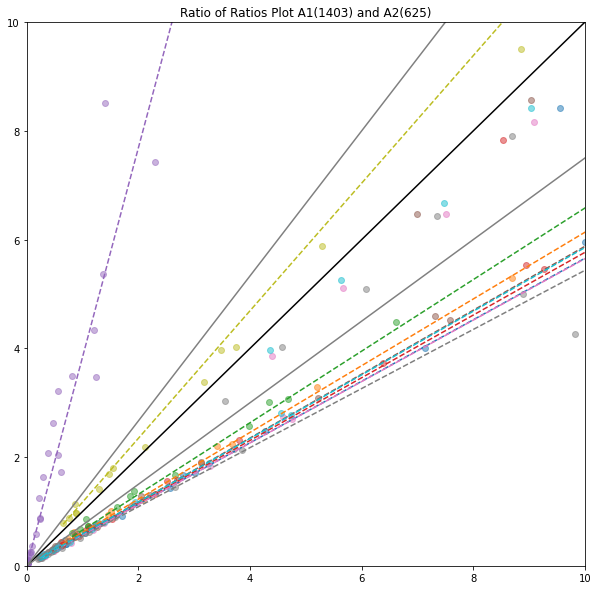

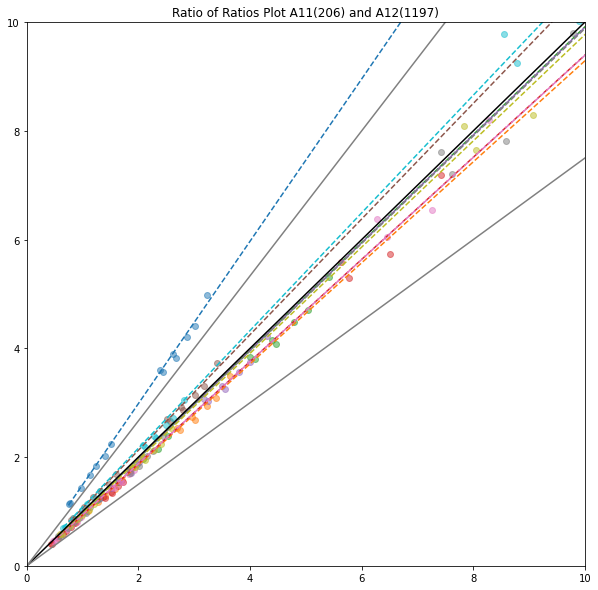

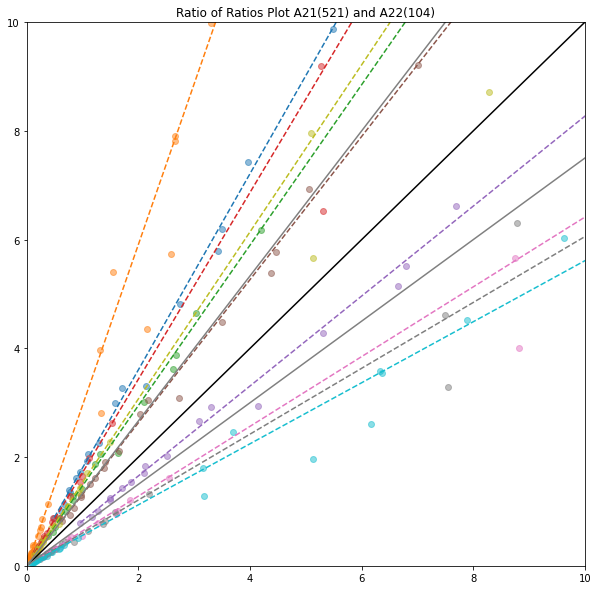

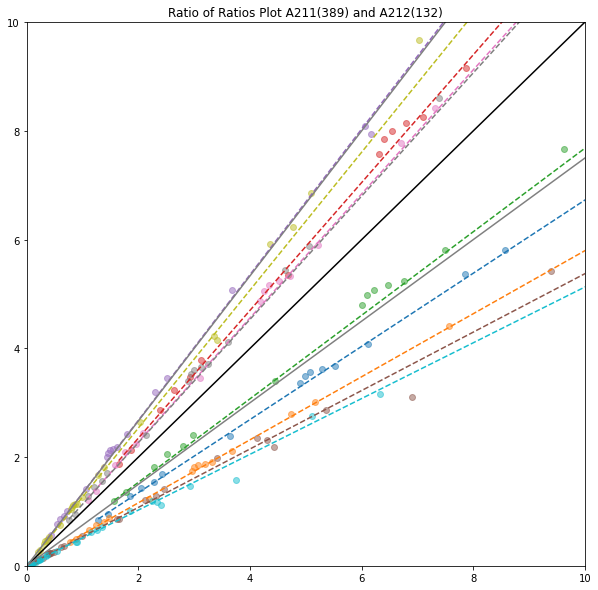

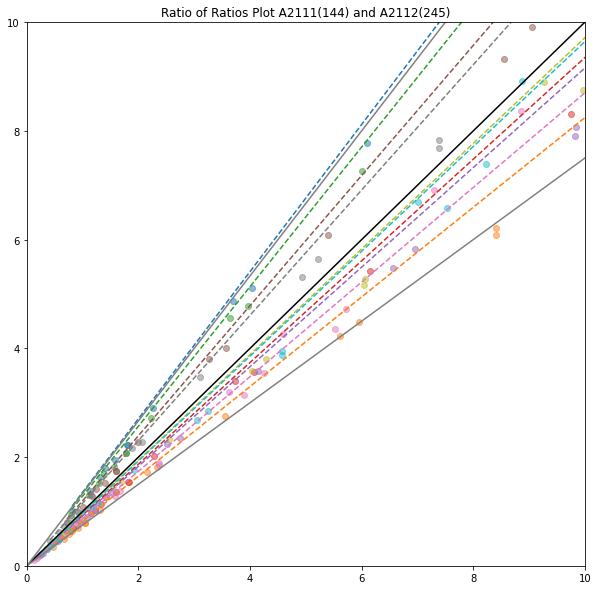

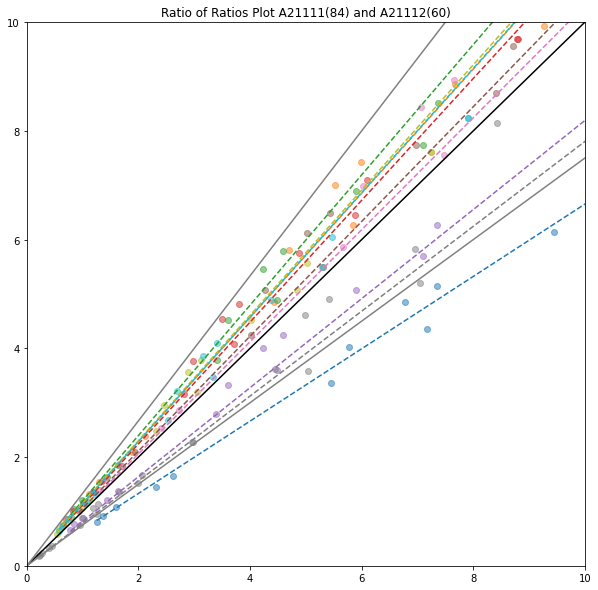

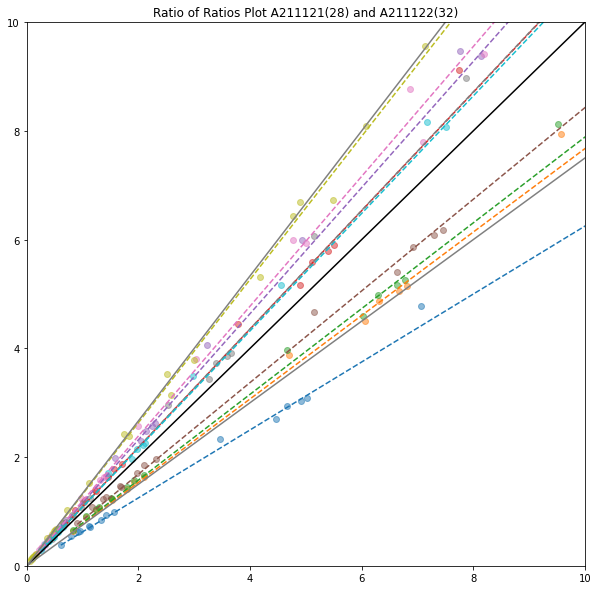

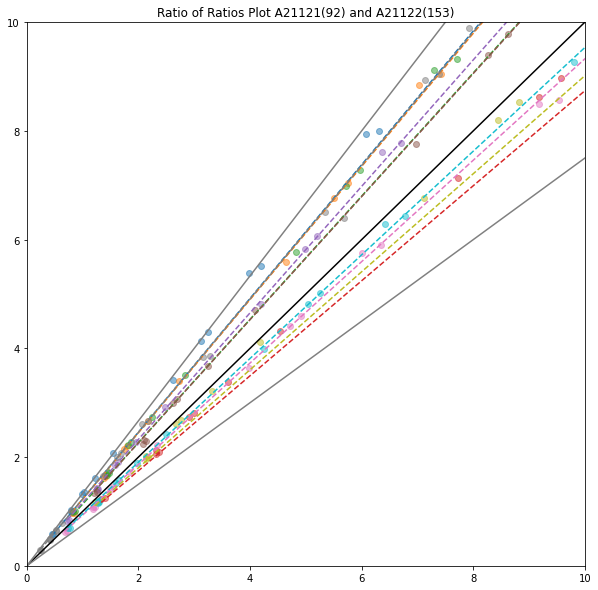

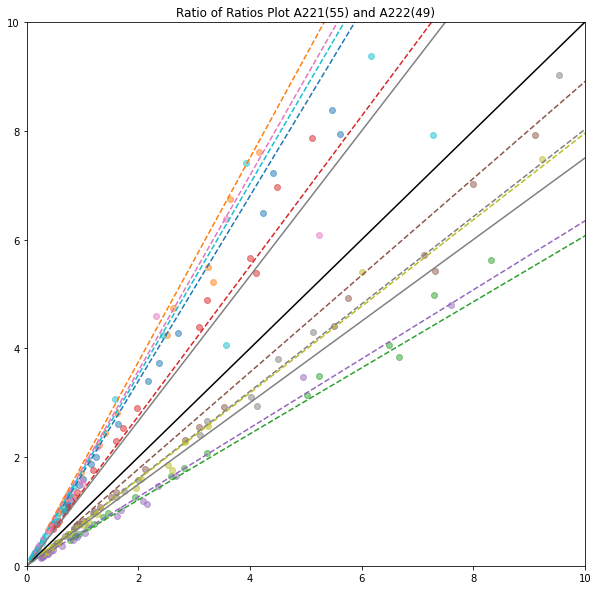

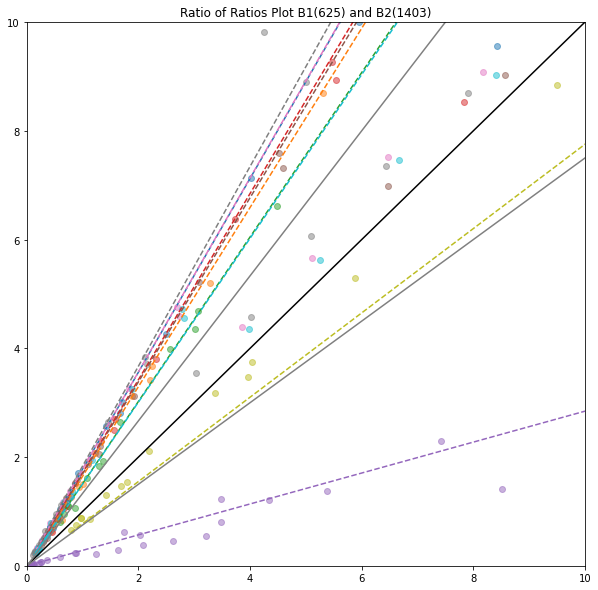

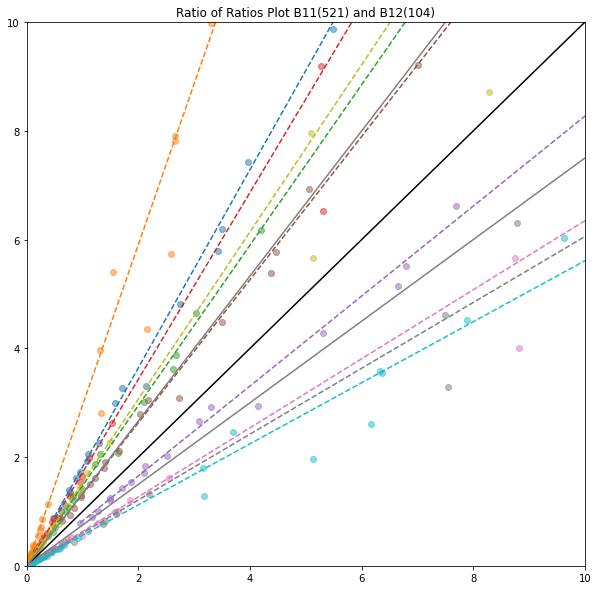

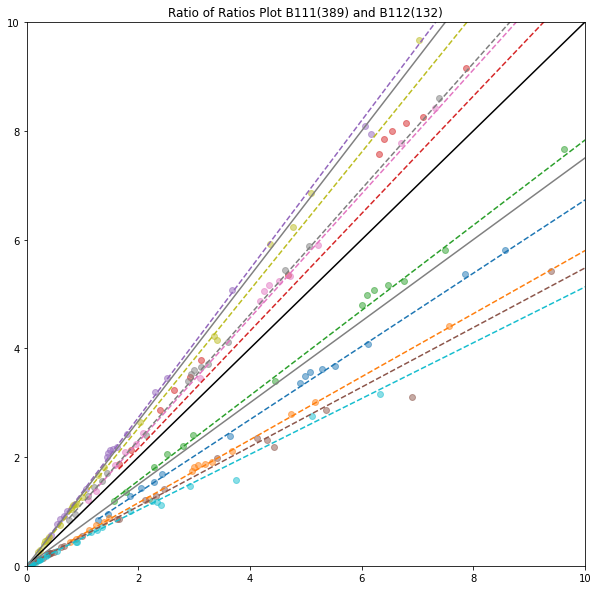

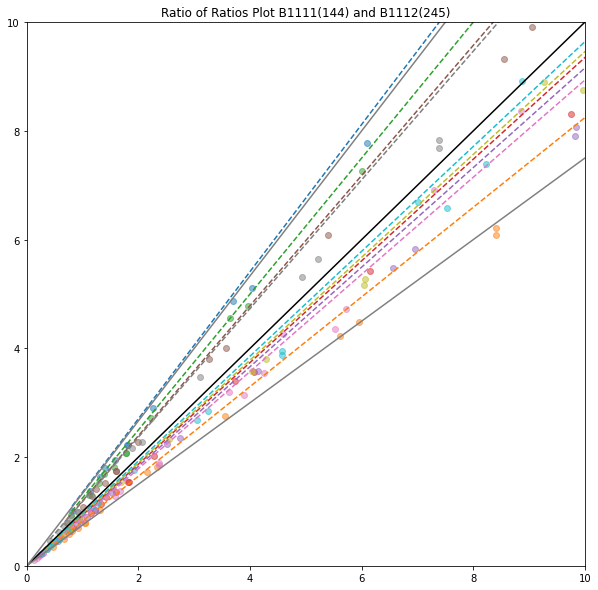

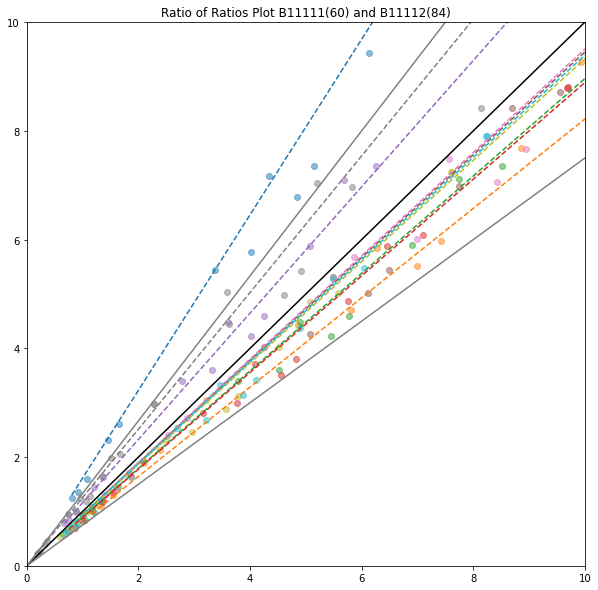

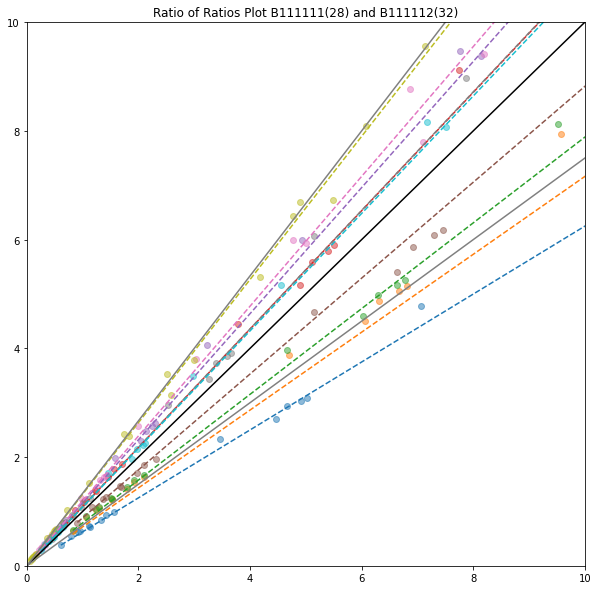

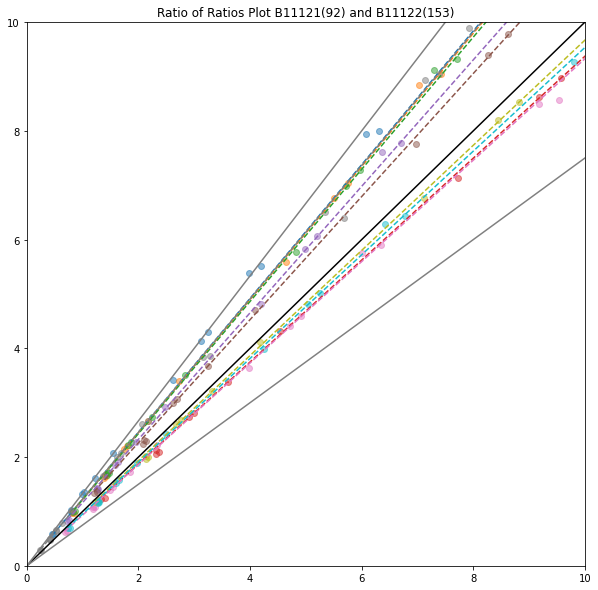

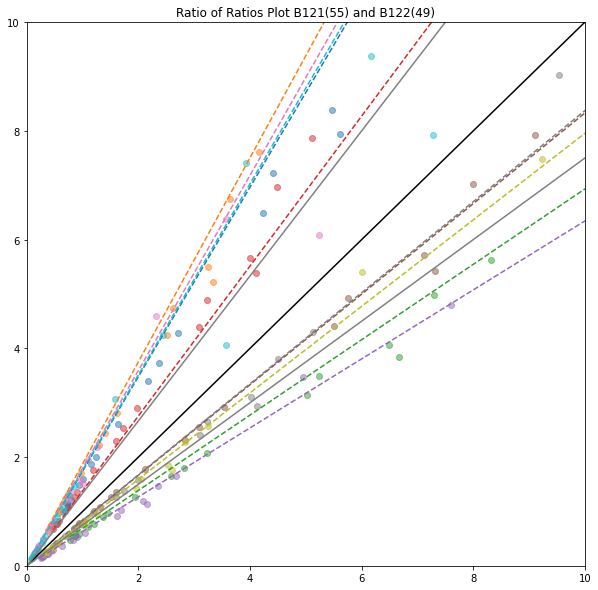

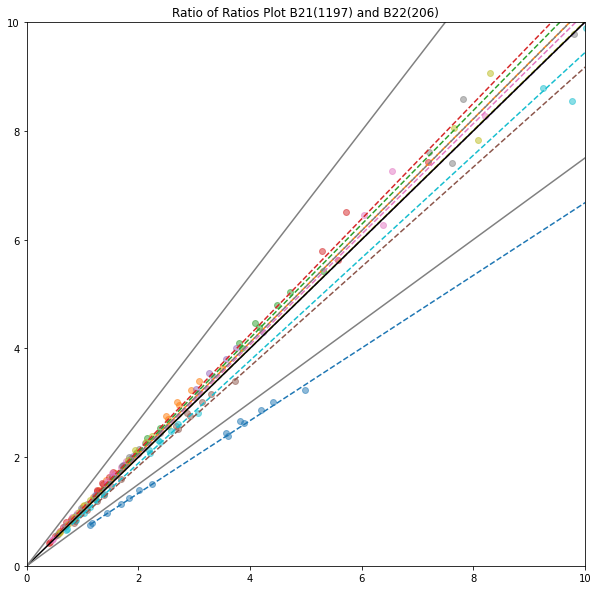

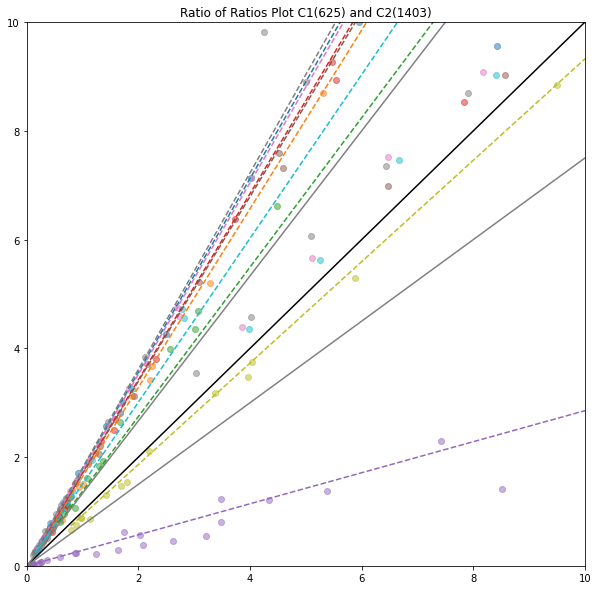

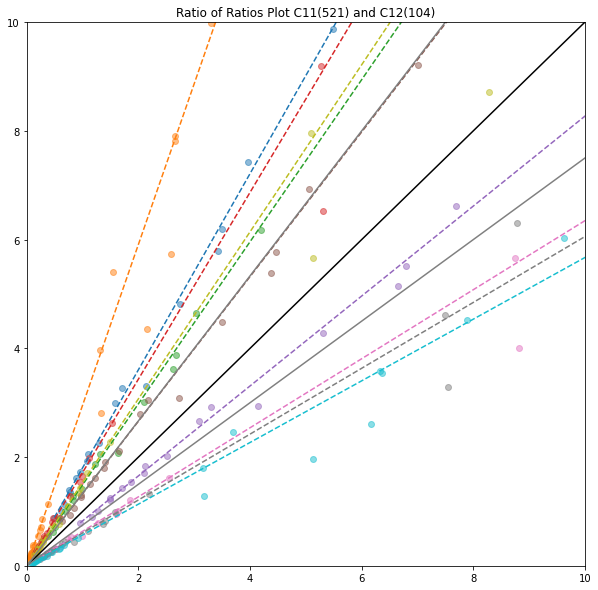

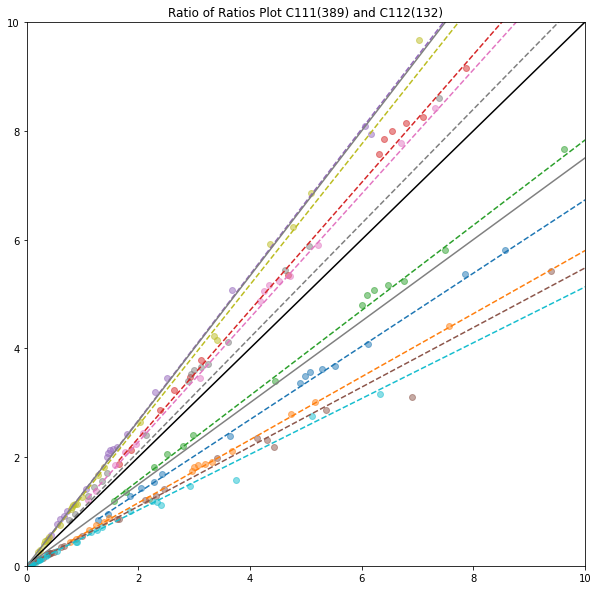

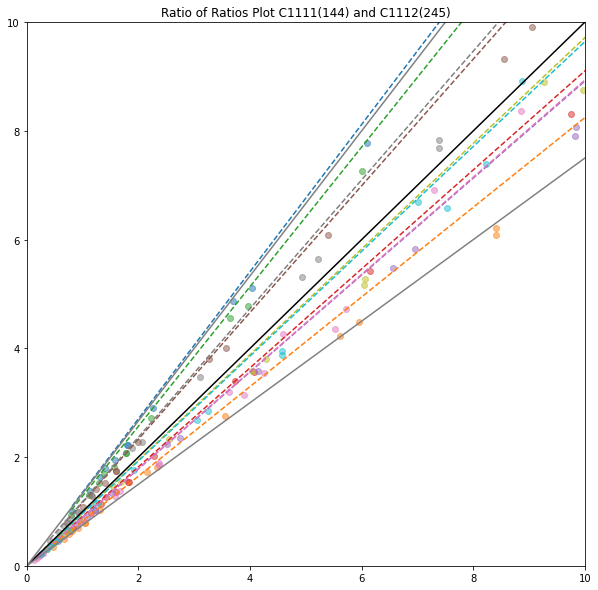

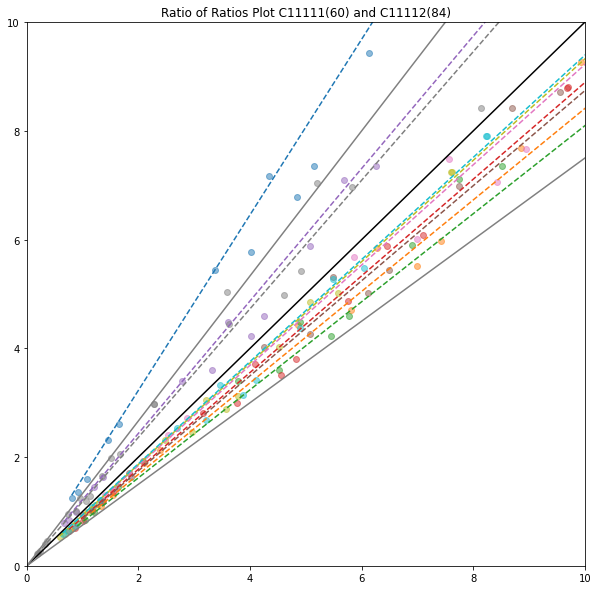

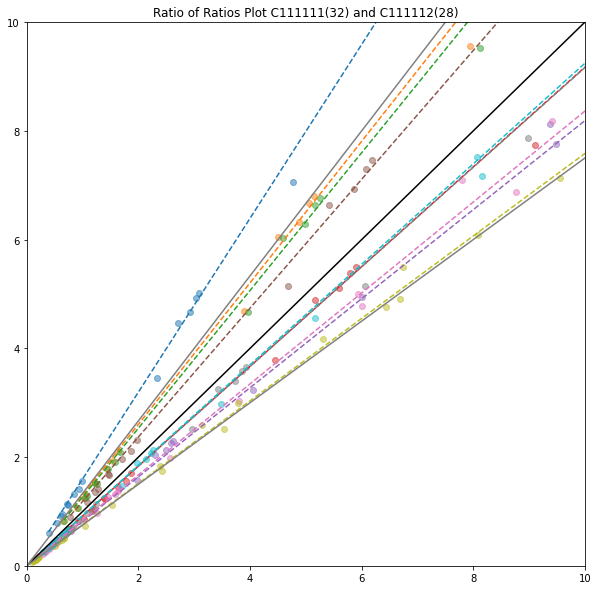

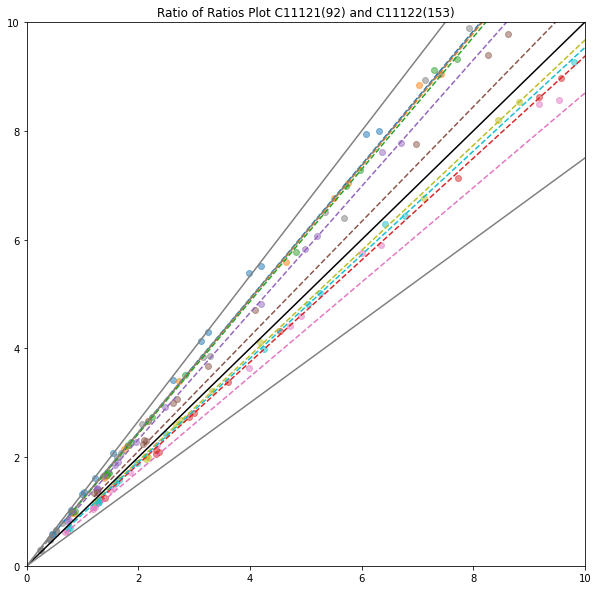

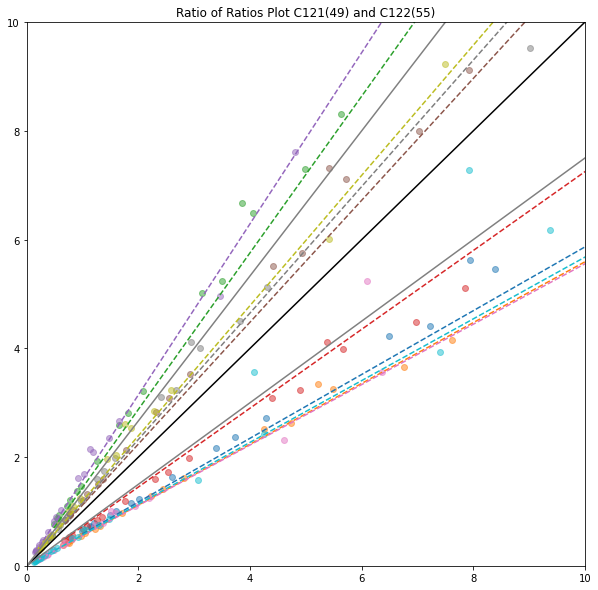

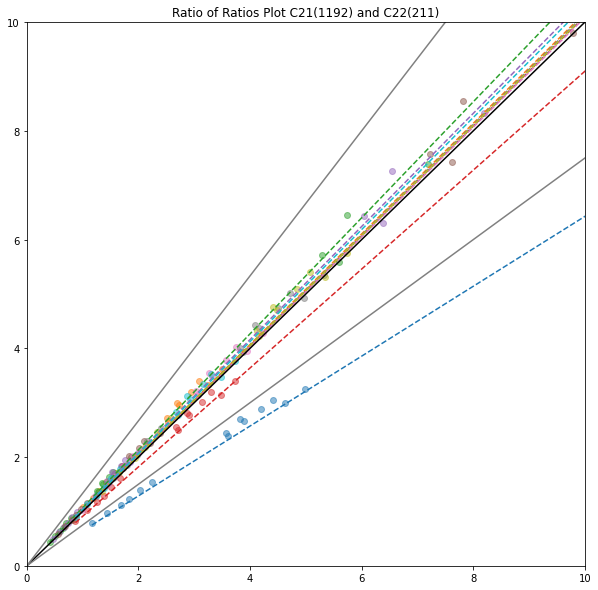

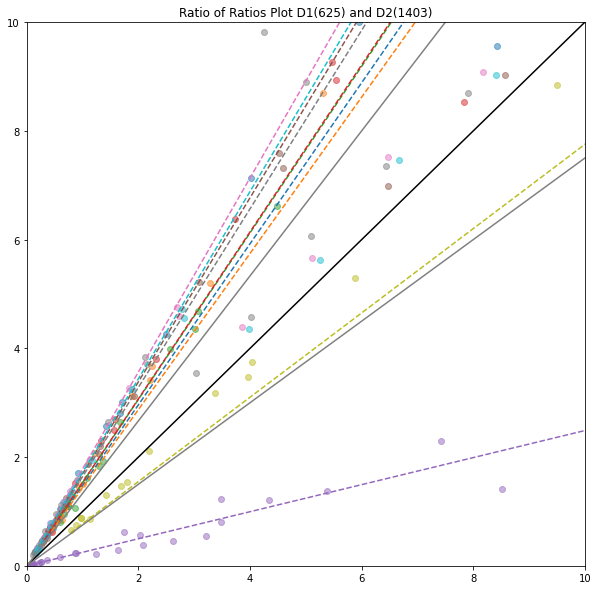

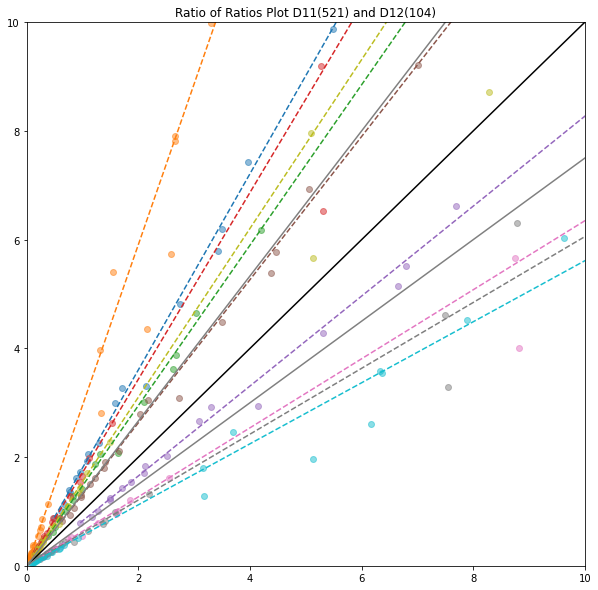

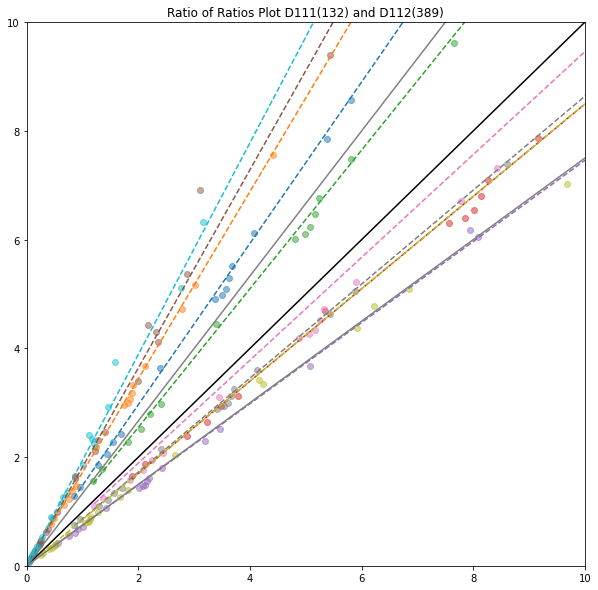

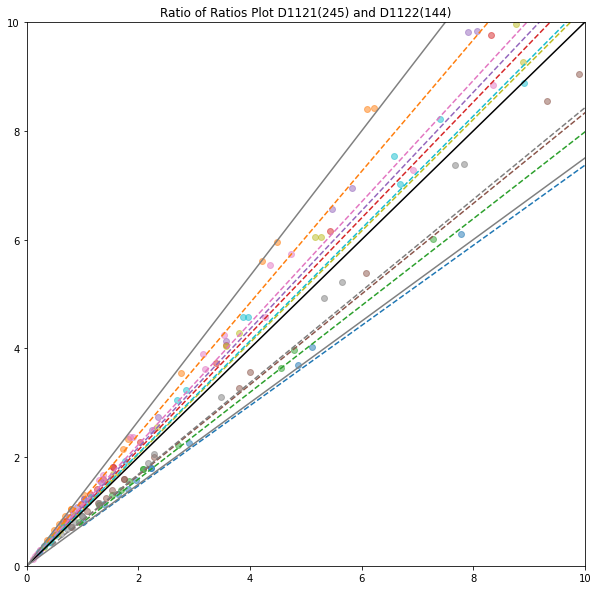

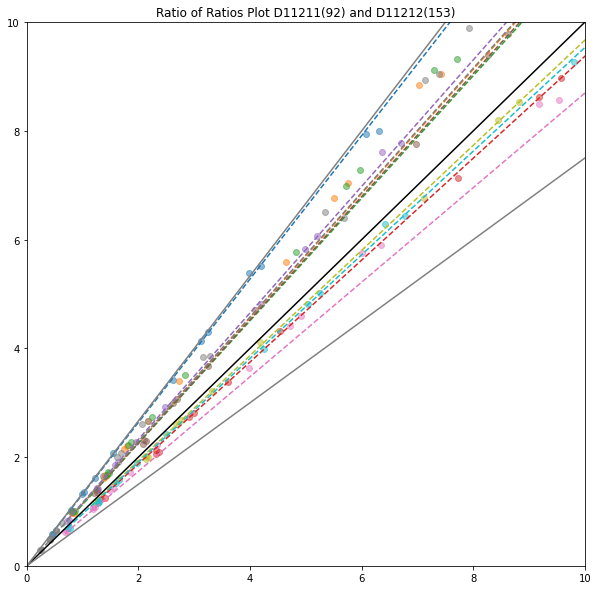

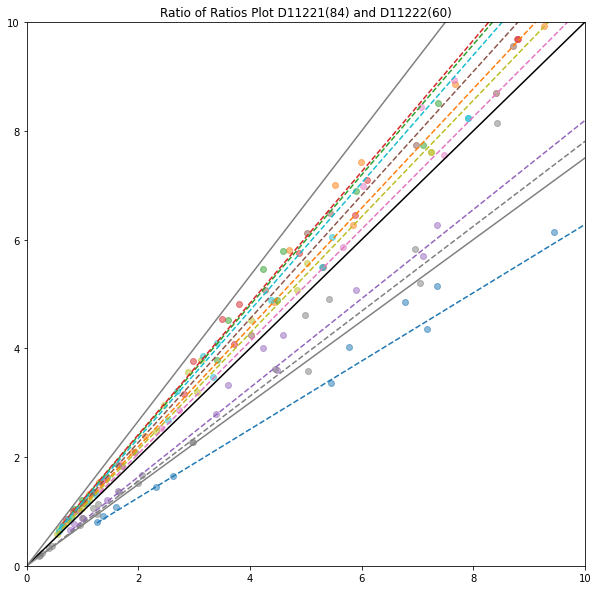

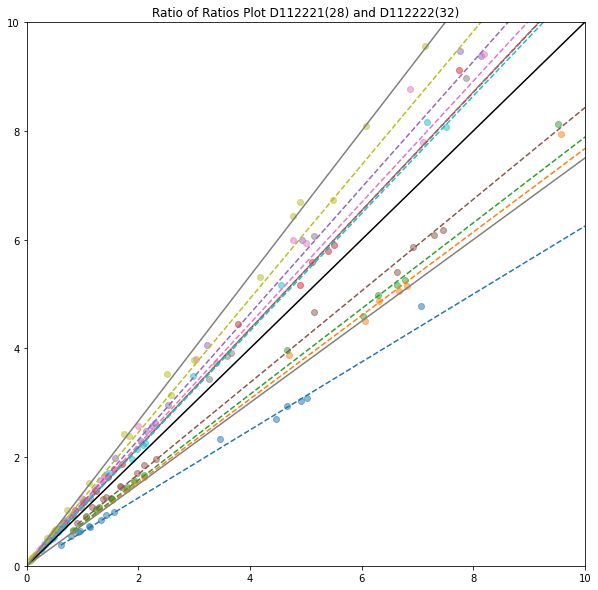

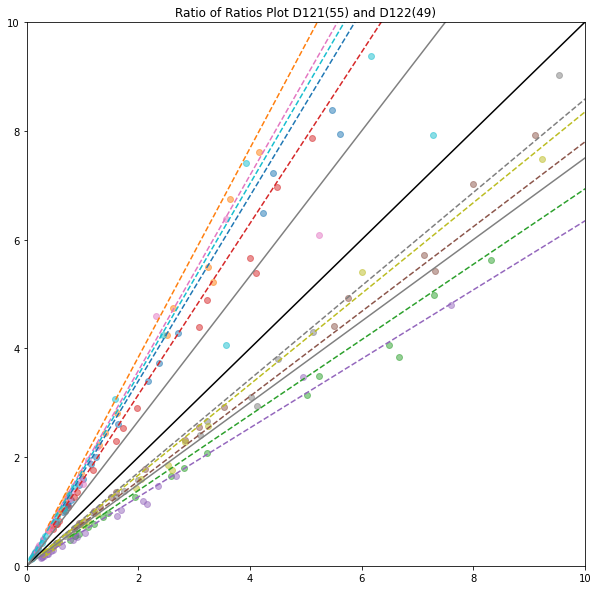

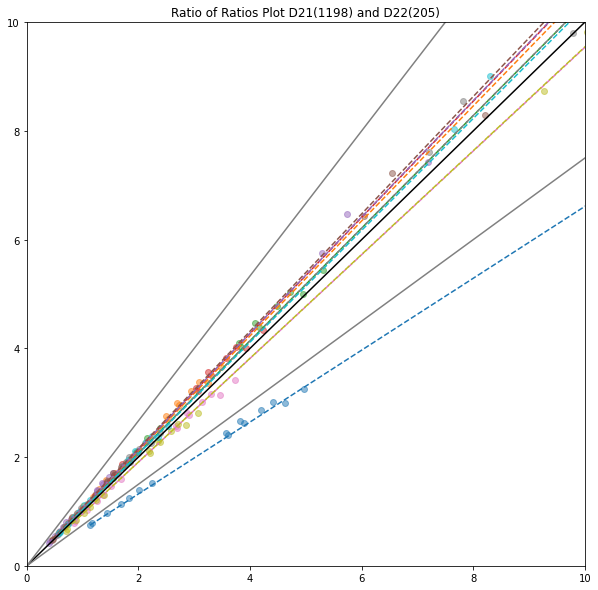

In [51]:
final_populations_A = recursive_em_split(
    all_data, cells, 
    threshold=3/4, max_depth=10, name="A"
)

final_populations_B = recursive_em_split(
    all_data, cells, 
    threshold=3/4, max_depth=10, name="B"
)

final_populations_C = recursive_em_split(
    all_data, cells, 
    threshold=3/4, max_depth=10, name="C"
)

final_populations_D = recursive_em_split(
    all_data, cells, 
    threshold=3/4, max_depth=10, name="D"
)

In [52]:
#pop_no_WGS_dict = reassign_cells(all_data_no_WGS, equi_bins_populations)

In [53]:
A_dict = reassign_cells(all_data, final_populations_A)
B_dict = reassign_cells(all_data, final_populations_B)
C_dict = reassign_cells(all_data, final_populations_C)
D_dict = reassign_cells(all_data, final_populations_D)

In [54]:
A_dict.keys(), B_dict.keys()

(dict_keys(['A11', 'A12', 'A21111', 'A211121', 'A211122', 'A2112', 'A212', 'A221', 'A222']),
 dict_keys(['B111111', 'B111112', 'B11112', 'B1112', 'B112', 'B121', 'B122', 'B21', 'B22']))


Overlap Matrix (A rows vs B cols):
Pop      B111111 B111112  B11112   B1112    B112    B121    B122     B21     B22
A11            0       0       0       0       0       0       0       0     230
A12            0       0       0       0       0       0       0    1212       0
A21111         0       0     112       0       0       0       0       0       0
A211121       31       0       0       0       0       0       0       0       0
A211122        0      44       0       0       0       0       0       0       0
A2112          0       0       0     251       0       0       0       0       0
A212           0       0       0       0     130       0       0       0       0
A221           0       0       0       0       0      61       0       0       0
A222           0       0       0       0       0       0      57       0       0


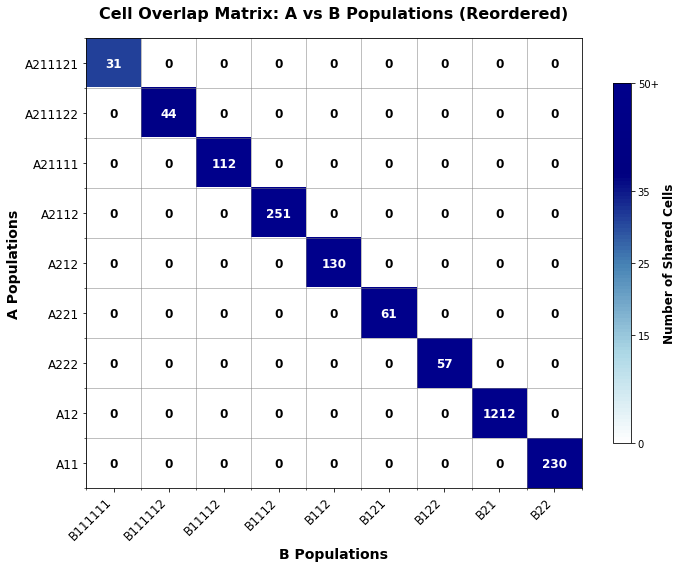

In [55]:
overlap_df = plot_overlap_matrix_figure(A_dict, B_dict, name1="A", name2="B")

In [56]:
previous_dict = {}
for cluster in previous_df['population'].unique():
    print(cluster)
    cells_in_cluster = previous_df[previous_df['population'] == cluster]['cell'].tolist()
    previous_dict[cluster] = {
        'cells': cells_in_cluster
    }
previous_dict["collisions"] = {"cells": [c1+"_"+c2 for c1, c2 in zip(normal_sample, tumor_sample)]}

    


C11
C12
C2111
C21121
C211221
C211222
C212
C221
C222


In [57]:
A_dict

{'A11': {'cells': ['AAAACCAGTGAGGAACT',
   'AAAACCATGGATGTAGC',
   'AAAACCGACCATTTAGG',
   'AAAACCGCCTCTAATGC',
   'AAAATGACTGGCAATGC',
   'AAAATGATGCACATATA',
   'AAAATGATTCAGGAACT',
   'AAAATGGTTCCCTCTGT',
   'AAAATGTAAGCTGCACG',
   'AAAGCAAAAGTACGTCT',
   'AAAGCAAACCGACGTTC',
   'AAAGCAATCCGGACAAT',
   'AAAGCATAATTTTATCT',
   'AACAAGAGAATTTGATA',
   'AACAAGATGGATGTAAT',
   'AACCCGGGTGACGCATA',
   'AACCCGTTTACGACACA',
   'AACGATAACTTTCAACG',
   'AACGATGACTGGCTATC',
   'AACGGGAGCGTTAGTCG',
   'AACGGGTTCGGCAATAT',
   'AATAGCAGCCTCGATCG',
   'AATAGCGAACCCTCTTA',
   'AATAGCTTGCTGGAAGA',
   'AATGAGATGCACATAGT',
   'ACAGGGTAAACCGATCG',
   'ACAGGGTTGAGCTCTAC',
   'ACAGGGTTTACGTCACT',
   'ACCAGAATCGAGTCTGT',
   'ACCAGAGTGCAATTAGG',
   'ACCAGATGGCGACTTAC',
   'ACCAGATTGGCCCTAAG',
   'ACCCTTAGTGAGGTAAT',
   'ACCCTTTTGGCCTAATG',
   'ACGTCCAGTTTGAGTCG',
   'ACGTCCTTTGGAGCAAC',
   'AGCAATAGTGAGGTAAT',
   'AGCAATATGCACTGTGG',
   'AGCAATTTGCTGGATTA',
   'AGCAGGCGACTTTAAGC',
   'AGCGAAGAACAAAGTGT',


In [58]:
previos_A = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_A.txt", sep="\t")


In [59]:
previous_A_dict = {}
for cluster in previos_A['population'].unique():
    print(cluster)
    cells_in_cluster = previos_A[previos_A['population'] == cluster]['cell'].tolist()
    previous_A_dict[cluster] = {
        'cells': cells_in_cluster
    }

previous_A_dict["collisions"] = {"cells": [c1+"_"+c2 for c1, c2 in zip(normal_sample, tumor_sample)]}

A11
A12
A211
A212
A221
A222



Overlap Matrix (A rows vs B cols):
Pop          C11     C12   C2111  C21121 C211221 C211222    C212    C221    C222collisions
B111111        0       0       0       0      30       0       0       0       0       1
B111112        0       0       0       0       0      41       0       0       0       3
B11112         0       0       0      87       0       0       0       0       0      25
B1112          0       0     243       0       0       0       0       0       0       8
B112           0       0       0       0       0       0     126       0       0       4
B121           0       0       0       0       0       0       0      58       0       3
B122           0       0       0       0       0       0       0       0      55       2
B21            0    1185       0       0       0       0       0       0       0      27
B22          203       0       0       0       0       0       0       0       0      27


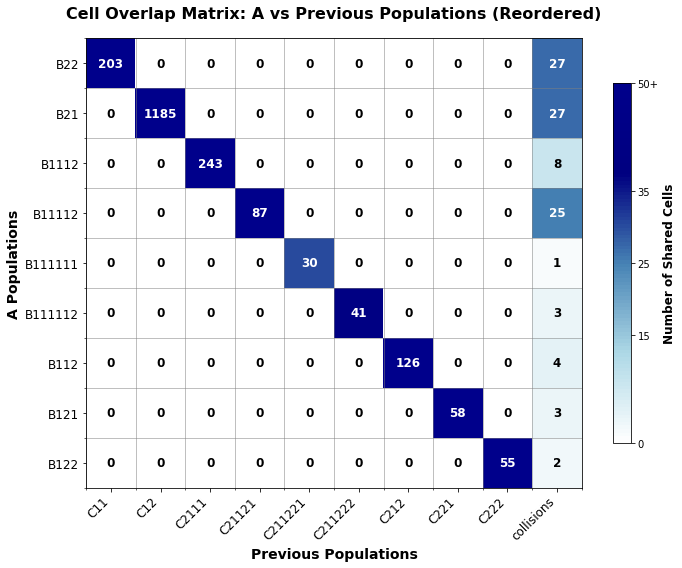

In [60]:
overlap_df = plot_overlap_matrix_figure(B_dict, previous_dict, name1="A", name2="Previous")


Overlap Matrix (A rows vs B cols):
Pop          A11     A12    A211    A212    A221    A222collisions
A11            0     203       0       0       0       0      27
A12         1185       0       0       0       0       0      27
A21111         4       7       1       0      71       4      25
A211121        0       2       0       0      28       0       1
A211122        0       3       0       2      36       0       3
A2112          0       2       0       0     241       0       8
A212           0       0       0       0       0     126       4
A221           0       0       0      58       0       0       3
A222           0       0      55       0       0       0       2


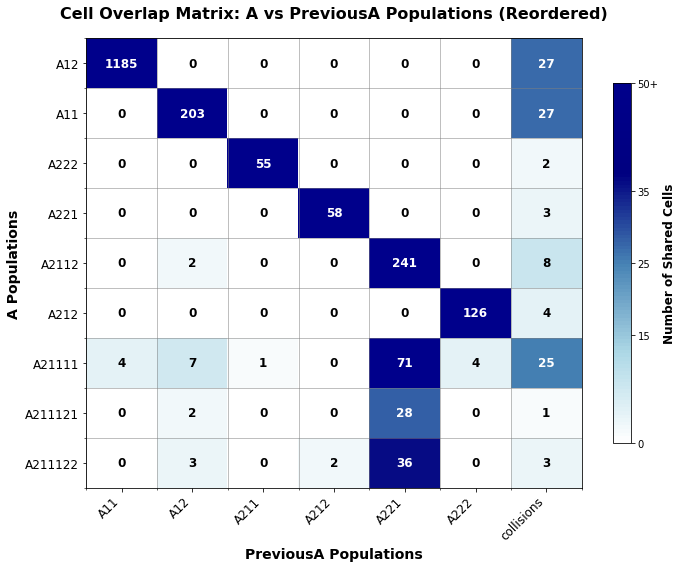

In [61]:
overlap_df = plot_overlap_matrix_figure(A_dict, previous_A_dict, name1="A", name2="PreviousA")


Overlap Matrix (A rows vs B cols):
Pop          A11     A12    A211    A212    A221    A222collisions
C111111        0       3       0       2      36       0       3
C111112        0       2       0       0      28       0       1
C11112         4       7       1       0      71       4      25
C1112          0       1       0       0     241       0       8
C112           0       0       0       0       0     126       4
C121           0       0      55       0       0       0       2
C122           0       0       0      58       0       0       3
C21         1178       2       0       0       0       0      25
C22            7     202       0       0       0       0      29


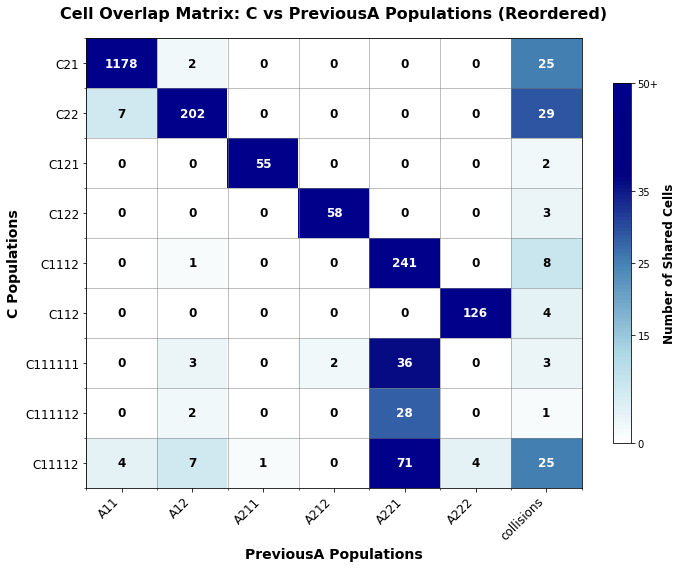

In [62]:
overlap_df = plot_overlap_matrix_figure(C_dict, previous_A_dict, name1="C", name2="PreviousA")


Overlap Matrix (A rows vs B cols):
Pop          A11     A12    A211    A212    A221    A222collisions
D111           0       0       0       0       0     126       4
D1121          0       2       0       0     241       0       8
D11221         4       7       1       0      71       4      24
D112221        0       2       0       0      28       0       1
D112222        0       3       0       2      36       0       3
D121           0       0       0      58       0       0       3
D122           0       0      55       0       0       0       2
D21         1185       2       0       0       0       0      27
D22            0     201       0       0       0       0      28


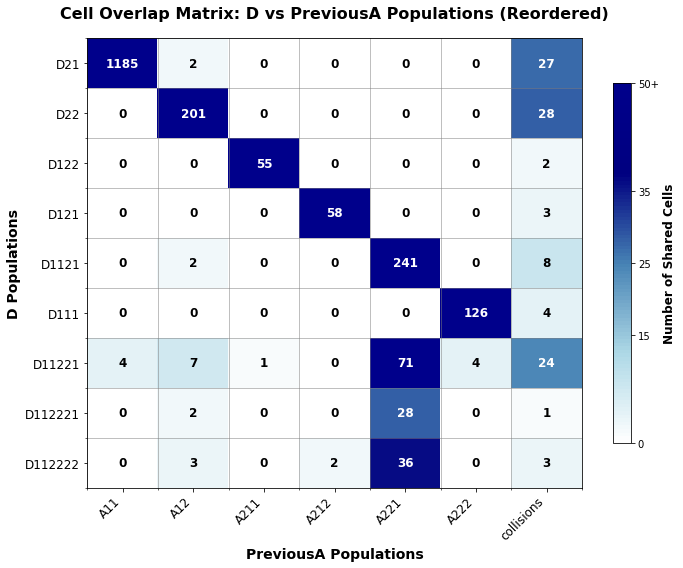

In [63]:
overlap_df = plot_overlap_matrix_figure(D_dict, previous_A_dict, name1="D", name2="PreviousA")

In [64]:
for cl in A_dict.keys():
    col_cells = [c for c in A_dict[cl]['cells'] if '_' in c]
    count = 0
    for c in col_cells:
        t = c.split('_')[1]
        if t in A_dict[cl]['cells']:
            count += 1
        
    print(cl, len(col_cells), count)

A11 27 8
A12 27 0
A21111 25 4
A211121 1 1
A211122 3 3
A2112 8 7
A212 4 4
A221 3 3
A222 2 2


In [65]:
#stop

In [66]:
#overlap_df = plot_overlap_matrix_figure(A_dict, C_dict, name1="A", name2="C")

In [67]:
#overlap_df = plot_overlap_matrix_figure(A_dict, D_dict, name1="A", name2="D")

In [68]:
#overlap_df = plot_overlap_matrix_figure(B_dict, C_dict, name1="B", name2="C")

In [69]:
#overlap_df = plot_overlap_matrix_figure(B_dict, D_dict, name1="B", name2="D")

In [70]:
#overlap_df = plot_overlap_matrix_figure(D_dict, C_dict, name1="D", name2="C")

In [71]:
from copy_number import (
    make_unif_dict, 
    compute_read_counts_relative_to_normal,
    compute_average_segment_counts, 
    compute_optimal_ploidy_and_profile,
    create_copy_number_matrix_fast
)
print("=== Population Set A Analysis ===")
avg_counts_A, ratios_A, normal_A = compute_average_segment_counts(all_data, A_dict, data)
relative_counts_A = compute_read_counts_relative_to_normal(all_data, A_dict, normal_A)
print("=== Population Set B Analysis ===")
avg_counts_B, ratios_B, normal_B = compute_average_segment_counts(all_data, B_dict, data)
relative_counts_B = compute_read_counts_relative_to_normal(all_data, B_dict, normal_B)
print("=== Population Set C Analysis ===")
avg_counts_C, ratios_C, normal_C = compute_average_segment_counts(all_data, C_dict, data)
relative_counts_C = compute_read_counts_relative_to_normal(all_data, C_dict, normal_C)
print("=== Population Set D Analysis ===")
avg_counts_D, ratios_D, normal_D = compute_average_segment_counts(all_data, D_dict, data)
relative_counts_D = compute_read_counts_relative_to_normal(all_data, D_dict, normal_D)



=== Population Set A Analysis ===
Normal population identified as: A12
Mean read count ratio for population A11 relative to normal (A12): 1.27
Mean read count ratio for population A12 relative to normal (A12): 1.00
Mean read count ratio for population A21111 relative to normal (A12): 1.64
Mean read count ratio for population A211121 relative to normal (A12): 1.06
Mean read count ratio for population A211122 relative to normal (A12): 1.45
Mean read count ratio for population A2112 relative to normal (A12): 1.24
Mean read count ratio for population A212 relative to normal (A12): 1.48
Mean read count ratio for population A221 relative to normal (A12): 1.49
Mean read count ratio for population A222 relative to normal (A12): 1.22
=== Population Set B Analysis ===
Normal population identified as: B21
Mean read count ratio for population B111111 relative to normal (B21): 1.06
Mean read count ratio for population B111112 relative to normal (B21): 1.45
Mean read count ratio for population B1111

In [72]:
# Get all population ratio columns (excluding normal population) for A
pop_ratio_cols_A = [col for col in ratios_A.columns if col.endswith('_ratio') and col != f"{normal_A}_ratio"]

# Store results
ploidy_results_A = {}
profile_dfs_A = {}

print(f"Normal population: {normal_A}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_A]}")

for pop_col in pop_ratio_cols_A:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Compute optimal ploidy
    optimal_m, min_cost, results_df, cost_results, _ = compute_optimal_ploidy_and_profile(
        ratios_A, 
        relative_counts_A,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1
    )
    
    # Store results
    ploidy_results_A[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results
    }
    profile_dfs_A[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")

# Get all population ratio columns (excluding normal population) for B
pop_ratio_cols_B = [col for col in ratios_B.columns if col.endswith('_ratio') and col != f"{normal_B}_ratio"]

# Store results
ploidy_results_B = {}
profile_dfs_B = {}

print(f"Normal population: {normal_B}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_B]}")

for pop_col in pop_ratio_cols_B:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Compute optimal ploidy
    optimal_m, min_cost, results_df, cost_results, _ = compute_optimal_ploidy_and_profile(
        ratios_B, 
        relative_counts_B,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1
    )
    
    # Store results
    ploidy_results_B[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results
    }
    profile_dfs_B[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")

# For Population Set C
pop_ratio_cols_C = [col for col in ratios_C.columns if col.endswith('_ratio') and col != f"{normal_C}_ratio"]
ploidy_results_C = {}
profile_dfs_C = {}

print(f"Normal population: {normal_C}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_C]}")

for pop_col in pop_ratio_cols_C:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Compute optimal ploidy
    optimal_m, min_cost, results_df, cost_results, _ = compute_optimal_ploidy_and_profile(
        ratios_C, 
        relative_counts_C,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1
    )
    
    # Store results
    ploidy_results_C[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results
    }
    profile_dfs_C[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")


# Get all population ratio columns (excluding normal population) for D
pop_ratio_cols_D = [col for col in ratios_D.columns if col.endswith('_ratio') and col != f"{normal_D}_ratio"]

# Store results
ploidy_results_D = {}
profile_dfs_D = {}

print(f"Normal population: {normal_D}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_D]}")

for pop_col in pop_ratio_cols_D:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Compute optimal ploidy
    optimal_m, min_cost, results_df, cost_results, _ = compute_optimal_ploidy_and_profile(
        ratios_D, 
        relative_counts_D,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1
    )
    
    # Store results
    ploidy_results_D[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results
    }
    profile_dfs_D[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")




Normal population: A12
Populations to optimize: ['A11', 'A21111', 'A211121', 'A211122', 'A2112', 'A212', 'A221', 'A222']

Optimizing ploidy for population: A11
Target multiplier based on relative counts: 2.53

Optimal Results for A11:
Optimal multiplier (m): 2.900
Minimum cost: 5.51e+07
Average copy number: 2.95
Found 5 local minima
Optimal multiplier for A11: 2.900

Optimizing ploidy for population: A21111
Target multiplier based on relative counts: 3.29

Optimal Results for A21111:
Optimal multiplier (m): 2.700
Minimum cost: 1.28e+08
Average copy number: 2.71
Found 4 local minima
Optimal multiplier for A21111: 2.700

Optimizing ploidy for population: A211121
Target multiplier based on relative counts: 2.12

Optimal Results for A211121:
Optimal multiplier (m): 1.700
Minimum cost: 3.14e+07
Average copy number: 1.69
Found 5 local minima
Optimal multiplier for A211121: 1.700

Optimizing ploidy for population: A211122
Target multiplier based on relative counts: 2.91

Optimal Results for A

In [73]:
# from copy_number import create_copy_number_matrix_fast
# from visualization import plot_copy_number_heatmap, plot_overlap_matrix_figure

# # Then you can use these functions in your analysis:

# # Create heatmaps for both population sets
# print("=== Creating Copy Number Heatmaps ===")

# # For Population Set A
# heatmap_df_A, cell_mapping_A, boundaries_A, segment_info_A = create_copy_number_matrix_fast(
#     all_data, 
#     A_dict, 
#     ratios_A, 
#     {f"{pop}_ratio": ploidy_results_A[pop]['optimal_multiplier'] for pop in ploidy_results_A.keys()}, 
#     normal_A
# )

# print(f"Heatmap A matrix dimensions: {heatmap_df_A.shape[0]} segments × {heatmap_df_A.shape[1]} cells")

# plot_copy_number_heatmap(
#     heatmap_df_A, 
#     boundaries_A, 
#     segment_info_A,
#     title="Copy Number Heatmap: Population Set A"
# )

# # For Population Set B
# heatmap_df_B, cell_mapping_B, boundaries_B, segment_info_B = create_copy_number_matrix_fast(
#     all_data, 
#     B_dict, 
#     ratios_B, 
#     {f"{pop}_ratio": ploidy_results_B[pop]['optimal_multiplier'] for pop in ploidy_results_B.keys()}, 
#     normal_B
# )

# plot_copy_number_heatmap(
#     heatmap_df_B, 
#     boundaries_B, 
#     segment_info_B,
#     title="Copy Number Heatmap: Population Set B"
# ) 

# # For Population Set C
# heatmap_df_C, cell_mapping_C, boundaries_C, segment_info_C = create_copy_number_matrix_fast(
#     all_data, 
#     C_dict, 
#     ratios_C, 
#     {f"{pop}_ratio": ploidy_results_C[pop]['optimal_multiplier'] for pop in ploidy_results_C.keys()}, 
#     normal_C
# )       
# plot_copy_number_heatmap(
#     heatmap_df_C, 
#     boundaries_C, 
#     segment_info_C,
#     title="Copy Number Heatmap: Population Set C"
# )

# # For Population Set D
# heatmap_df_D, cell_mapping_D, boundaries_D, segment_info_D = create_copy_number_matrix_fast(
#     all_data, 
#     D_dict, 
#     ratios_D, 
#     {f"{pop}_ratio": ploidy_results_D[pop]['optimal_multiplier'] for pop in ploidy_results_D.keys()}, 
#     normal_D
# )

# print(f"Heatmap D matrix dimensions: {heatmap_df_D.shape[0]} segments × {heatmap_df_D.shape[1]} cells")

# plot_copy_number_heatmap(
#     heatmap_df_D, 
#     boundaries_D, 
#     segment_info_D,
#     title="Copy Number Heatmap: Population Set D"
# )

In [74]:
# # Get all population ratio columns (excluding normal population) for A
# pop_ratio_cols_A = [col for col in ratios_A.columns if col.endswith('_ratio') and col != f"{normal_A}_ratio"]

# # Store results
# ploidy_results_A = {}
# profile_dfs_A = {}

# print(f"Normal population: {normal_A}")
# print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_A]}")

# for pop_col in pop_ratio_cols_A:
#     pop_name = pop_col.replace('_ratio', '')
#     print(f"\n{'='*50}")
#     print(f"Optimizing ploidy for population: {pop_name}")
    
#     # Compute optimal ploidy
#     optimal_m, min_cost, results_df, cost_results, _ = compute_optimal_ploidy_and_profile(
#         ratios_A, 
#         relative_counts_A,
#         pop_col, 
#         m_range=[1.5, 6], 
#         step_size=0.1
#     )
    
#     # Store results
#     ploidy_results_A[pop_name] = {
#         'optimal_multiplier': optimal_m,
#         'min_cost': min_cost,
#         'cost_results': cost_results
#     }
#     profile_dfs_A[pop_name] = results_df
    
#     print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")


# # For Population Set A
# heatmap_df_A, cell_mapping_A, boundaries_A, segment_info_A = create_copy_number_matrix_fast(
#     all_data, 
#     A_dict, 
#     ratios_A, 
#     {f"{pop}_ratio": ploidy_results_A[pop]['optimal_multiplier'] for pop in ploidy_results_A.keys()}, 
#     normal_A
# )

# print(f"Heatmap A matrix dimensions: {heatmap_df_A.shape[0]} segments × {heatmap_df_A.shape[1]} cells")

# plot_copy_number_heatmap(
#     heatmap_df_A, 
#     boundaries_A, 
#     segment_info_A,
#     title="Copy Number Heatmap: Population Set A"
# )/

In [75]:
# # Get all population ratio columns (excluding normal population) for D
# pop_ratio_cols_D = [col for col in ratios_D.columns if col.endswith('_ratio') and col != f"{normal_D}_ratio"]

# # Store results
# ploidy_results_D = {}
# profile_dfs_D = {}

# print(f"Normal population: {normal_D}")
# print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_D]}")

# for pop_col in pop_ratio_cols_D:
#     pop_name = pop_col.replace('_ratio', '')
#     print(f"\n{'='*50}")
#     print(f"Optimizing ploidy for population: {pop_name}")
    
#     # Compute optimal ploidy
#     optimal_m, min_cost, results_df, cost_results, _ = compute_optimal_ploidy_and_profile(
#         ratios_D, 
#         relative_counts_D,
#         pop_col, 
#         m_range=[1.5, 6], 
#         step_size=0.1
#     )
    
#     # Store results
#     ploidy_results_D[pop_name] = {
#         'optimal_multiplier': optimal_m,
#         'min_cost': min_cost,
#         'cost_results': cost_results
#     }
#     profile_dfs_D[pop_name] = results_df
    
#     print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")


# # For Population Set D
# heatmap_df_D, cell_mapping_D, boundaries_D, segment_info_D = create_copy_number_matrix_fast(
#     all_data, 
#     D_dict, 
#     ratios_D, 
#     {f"{pop}_ratio": ploidy_results_D[pop]['optimal_multiplier'] for pop in ploidy_results_D.keys()}, 
#     normal_D
# )

# print(f"Heatmap D matrix dimensions: {heatmap_df_D.shape[0]} segments × {heatmap_df_D.shape[1]} cells")

# plot_copy_number_heatmap(
#     heatmap_df_D, 
#     boundaries_D, 
#     segment_info_D,
#     title="Copy Number Heatmap: Population Set D"
# )

In [76]:
# Save population assignments A_dict to a text file
output_file = f"../data/{tumor}/{tumor}_new_population_assignments_A_with_collisions.txt"
with open(output_file, 'w') as f:
    #header
    f.write("cell\tpopulation\n")
    for pop_name, details in A_dict.items():
        cell_list = details['cells']
        for cell in cell_list:
            f.write(f"{cell}\t{pop_name}\n")

#Save population assignments B_dict to a text file
output_file = f"../data/{tumor}/{tumor}_new_population_assignments_B_with_collisions.txt"
with open(output_file, 'w') as f:
    #header
    f.write("cell\tpopulation\n")
    for pop_name, details in B_dict.items():
        cell_list = details['cells']
        for cell in cell_list:
            f.write(f"{cell}\t{pop_name}\n")

#Save population assignments C_dict to a text file
output_file = f"../data/{tumor}/{tumor}_new_population_assignments_C_with_collisions.txt"
with open(output_file, 'w') as f:
    #header
    f.write("cell\tpopulation\n")
    for pop_name, details in C_dict.items():
        cell_list = details['cells']
        for cell in cell_list:
            f.write(f"{cell}\t{pop_name}\n")

#Save population assignments D_dict to a text file
output_file = f"../data/{tumor}/{tumor}_new_population_assignments_D_with_collisions.txt"
with open(output_file, 'w') as f:
    #header
    f.write("cell\tpopulation\n")
    for pop_name, details in D_dict.items():
        cell_list = details['cells']
        for cell in cell_list:
            f.write(f"{cell}\t{pop_name}\n")

# #Save population assignments pop_no_WGS_dict to a text file
# output_file = f"../data/{tumor}/{tumor}_population_assignments_equi_bins.txt"
# with open(output_file, 'w') as f:
#     #header
#     f.write("cell\tpopulation\n")
#     for pop_name, details in pop_no_WGS_dict.items():
#         cell_list = details['cells']
#         for cell in cell_list:
#             f.write(f"{cell}\t{pop_name}\n")